In [1]:
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import matplotlib.ticker as mticker
import numpy as np
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import cartopy.mpl.ticker as cticker
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
import pandas as pd

ERROR 1: PROJ: proj_create_from_database: Open of /global/home/users/toireasamarie/.conda/envs/regrid_env2/share/proj failed


In [2]:
file = '/global/scratch/users/toireasamarie/0.1x0.1_deg_gridded_datasets/final_datasets/a10_lowCF_scaled_grouped_2hour_pulses.parquet'
groups_df = pd.read_parquet(file, engine='pyarrow')

file ='/global/scratch/users/toireasamarie/0.1x0.1_deg_gridded_datasets/final_datasets/a10_lowCF_scaled_filtered_merged_with_incdec.parquet'
df = pd.read_parquet(file, engine='pyarrow')

In [3]:
df

,grid_lat,grid_lon,h_precip_mm,datetime,no2_mean,no2_std,no2_sem,snow_ice_fraction_mean,snow_ice_fraction_std,cv_no2,...,pct_sandy_clay,pct_sandy_clay_loam,pct_sandy_loam,pct_silt,pct_silt_loam,pct_silty_clay,pct_silty_clay_loam,state_name,pre_slope,sm_class
0,36.05,-91.15,NaN,2024-02-29 22:00:00,NaN,NaN,NaN,NaN,NaN,NaN,...,0.0,0.000000,0.757576,0.0,86.363636,0.757576,7.575758,Arkansas,NaN,None
1,36.05,-91.15,NaN,2024-02-29 23:00:00,NaN,NaN,NaN,NaN,NaN,NaN,...,0.0,0.000000,0.757576,0.0,86.363636,0.757576,7.575758,Arkansas,NaN,None
2,36.05,-91.15,NaN,2024-03-01 00:00:00,NaN,NaN,NaN,NaN,NaN,NaN,...,0.0,0.000000,0.757576,0.0,86.363636,0.757576,7.575758,Arkansas,NaN,None
3,36.05,-91.15,NaN,2024-03-01 01:00:00,NaN,NaN,NaN,NaN,NaN,NaN,...,0.0,0.000000,0.757576,0.0,86.363636,0.757576,7.575758,Arkansas,NaN,None
4,36.05,-91.15,NaN,2024-03-01 02:00:00,NaN,NaN,NaN,NaN,NaN,NaN,...,0.0,0.000000,0.757576,0.0,86.363636,0.757576,7.575758,Arkansas,NaN,None
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
33395116,48.95,-96.85,0.345,2024-07-31 19:00:00,NaN,NaN,NaN,NaN,NaN,NaN,...,0.0,1.515152,88.636364,0.0,0.000000,0.000000,0.000000,Minnesota,NaN,None
33395117,48.95,-96.85,0.050,2024-07-31 20:00:00,NaN,NaN,NaN,NaN,NaN,NaN,...,0.0,1.515152,88.636364,0.0,0.000000,0.000000,0.000000,Minnesota,NaN,None
33395118,48.95,-96.85,0.000,2024-07-31 21:00:00,NaN,NaN,NaN,NaN,NaN,NaN,...,0.0,1.515152,88.636364,0.0,0.000000,0.000000,0.000000,Minnesota,NaN,None
33395119,48.95,-96.85,0.000,2024-07-31 22:00:00,NaN,NaN,NaN,NaN,NaN,NaN,...,0.0,1.515152,88.636364,0.0,0.000000,0.000000,0.000000,Minnesota,NaN,None


In [4]:
df.columns

Index(['grid_lat', 'grid_lon', 'h_precip_mm', 'datetime', 'no2_mean',
       'no2_std', 'no2_sem', 'snow_ice_fraction_mean', 'snow_ice_fraction_std',
       'cv_no2', 'datetime_local', 'local_hour', 'no2_scaled_by_hour',
       'pulse_start', 'sm_surface', 'surface_temp', 'soil_temp_layer1',
       'WFPS_c', 'dominant_texture', 'pct_clay', 'pct_clay_loam', 'pct_loam',
       'pct_loamy_sand', 'pct_sand', 'pct_sandy_clay', 'pct_sandy_clay_loam',
       'pct_sandy_loam', 'pct_silt', 'pct_silt_loam', 'pct_silty_clay',
       'pct_silty_clay_loam', 'state_name', 'pre_slope', 'sm_class'],
      dtype='object')

In [5]:
groups_df

,grid_lat,grid_lon,h_precip_mm,datetime,no2_mean,no2_std,no2_sem,snow_ice_fraction_mean,snow_ice_fraction_std,cv_no2,...,pct_sandy_loam,pct_silt,pct_silt_loam,pct_silty_clay,pct_silty_clay_loam,state_name,pre_slope,sm_class,time_num,group_id
0,37.35,-100.85,0.000,2024-03-13 16:00:00,2.173031e+15,6.369229e+14,1.273846e+14,0.0,0.0,0.293103,...,0.000000,0.0,75.000000,0.000000,22.727273,Kansas,-0.000005,decreasing,0.0,0
1,39.35,-92.75,0.000,2024-03-16 15:00:00,4.694567e+15,8.246832e+14,1.649366e+14,0.0,0.0,0.175668,...,0.000000,0.0,77.272727,0.000000,20.454545,Missouri,0.000689,increasing,71.0,1
2,39.15,-92.95,0.000,2024-03-16 15:00:00,2.622688e+15,1.454574e+15,2.969137e+14,0.0,0.0,0.554612,...,5.303030,0.0,71.969697,2.272727,11.363636,Missouri,0.000744,increasing,71.0,3
3,39.15,-92.85,0.000,2024-03-16 15:00:00,2.632403e+15,1.870482e+15,3.740963e+14,0.0,0.0,0.710561,...,1.388889,0.0,88.888889,0.694444,4.166667,Missouri,0.000872,increasing,71.0,3
4,39.15,-93.15,0.000,2024-03-16 15:00:00,2.643212e+15,1.089365e+15,2.178731e+14,0.0,0.0,0.412137,...,0.000000,0.0,100.000000,0.000000,0.000000,Missouri,0.000546,increasing,71.0,3
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2004,40.85,-95.05,0.000,2024-07-19 15:00:00,3.003975e+15,5.779969e+14,1.155994e+14,0.0,0.0,0.192411,...,0.000000,0.0,9.917355,0.000000,90.082645,Iowa,-0.000296,decreasing,3071.0,2004
2005,40.95,-94.75,0.000,2024-07-19 16:00:00,2.530260e+15,9.967452e+14,2.417462e+14,0.0,0.0,0.393930,...,0.000000,0.0,14.583333,0.000000,84.722222,Iowa,-0.000236,decreasing,3072.0,2005
2006,37.55,-98.35,0.105,2024-07-19 18:00:00,2.812737e+15,7.392236e+14,1.478447e+14,0.0,0.0,0.262813,...,45.454545,0.0,11.570248,0.000000,0.000000,Kansas,0.000606,increasing,3074.0,2006
2007,37.75,-98.65,0.000,2024-07-19 18:00:00,2.959582e+15,9.768195e+14,1.953639e+14,0.0,0.0,0.330053,...,81.818182,0.0,0.000000,0.000000,0.000000,Kansas,-0.000047,decreasing,3074.0,2007


In [6]:
groups_df.columns

Index(['grid_lat', 'grid_lon', 'h_precip_mm', 'datetime', 'no2_mean',
       'no2_std', 'no2_sem', 'snow_ice_fraction_mean', 'snow_ice_fraction_std',
       'cv_no2', 'datetime_local', 'local_hour', 'no2_scaled_by_hour',
       'pulse_start', 'sm_surface', 'surface_temp', 'soil_temp_layer1',
       'WFPS_c', 'dominant_texture', 'pct_clay', 'pct_clay_loam', 'pct_loam',
       'pct_loamy_sand', 'pct_sand', 'pct_sandy_clay', 'pct_sandy_clay_loam',
       'pct_sandy_loam', 'pct_silt', 'pct_silt_loam', 'pct_silty_clay',
       'pct_silty_clay_loam', 'state_name', 'pre_slope', 'sm_class',
       'time_num', 'group_id'],
      dtype='object')

In [7]:
import string

# sumary table to help pick events 
summary = (
    groups_df.groupby("group_id")
    .agg(
        sm_class=("sm_class", "first"),
        n_cells=("grid_lat", "nunique"),# spatial footprint size
        state=("state_name", "first"),
        t_start=("datetime", "min"),
        pre_slope=("pre_slope", "mean"),
        dominant_texture=("dominant_texture", "first"),
    )
    .reset_index()
)

print("=== Increasing events (sample) ===")
inc = summary[summary["sm_class"] == "increasing"].sort_values("n_cells", ascending=False)
print(inc[["group_id","n_cells","state","t_start","pre_slope","dominant_texture"]].head(30).to_string(index=False))

print("\n=== Decreasing events (sample) ===")
dec = summary[summary["sm_class"] == "decreasing"].sort_values("n_cells", ascending=False)
print(dec[["group_id","n_cells","state","t_start","pre_slope","dominant_texture"]].head(30).to_string(index=False))

print("\n--- Group size distribution ---")
print(summary.groupby("sm_class")["n_cells"].describe())

=== Increasing events (sample) ===
 group_id  n_cells        state             t_start  pre_slope dominant_texture
      733       15 South Dakota 2024-05-23 15:00:00   0.001627  silty clay loam
      877        9     Nebraska 2024-06-03 15:00:00   0.001086        clay loam
       76        8    Tennessee 2024-03-28 15:00:00   0.000727        silt loam
     1809        7     Nebraska 2024-07-09 15:00:00   0.000033  silty clay loam
     1348        7 South Dakota 2024-06-13 21:00:00   0.000270             loam
      980        7         Iowa 2024-06-06 16:00:00  -0.000521  silty clay loam
     1454        6 North Dakota 2024-06-19 15:00:00   0.000494             loam
      919        6     Nebraska 2024-06-02 20:00:00   0.000711  silty clay loam
     1997        5     Missouri 2024-07-18 15:00:00   0.000072             loam
     1654        5     Illinois 2024-07-07 15:00:00   0.000068        silt loam
      654        5 South Dakota 2024-05-23 15:00:00   0.001252             loam
     

/tmp/ipykernel_2072574/353019745.py:181: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0,0.02,1,0.99])


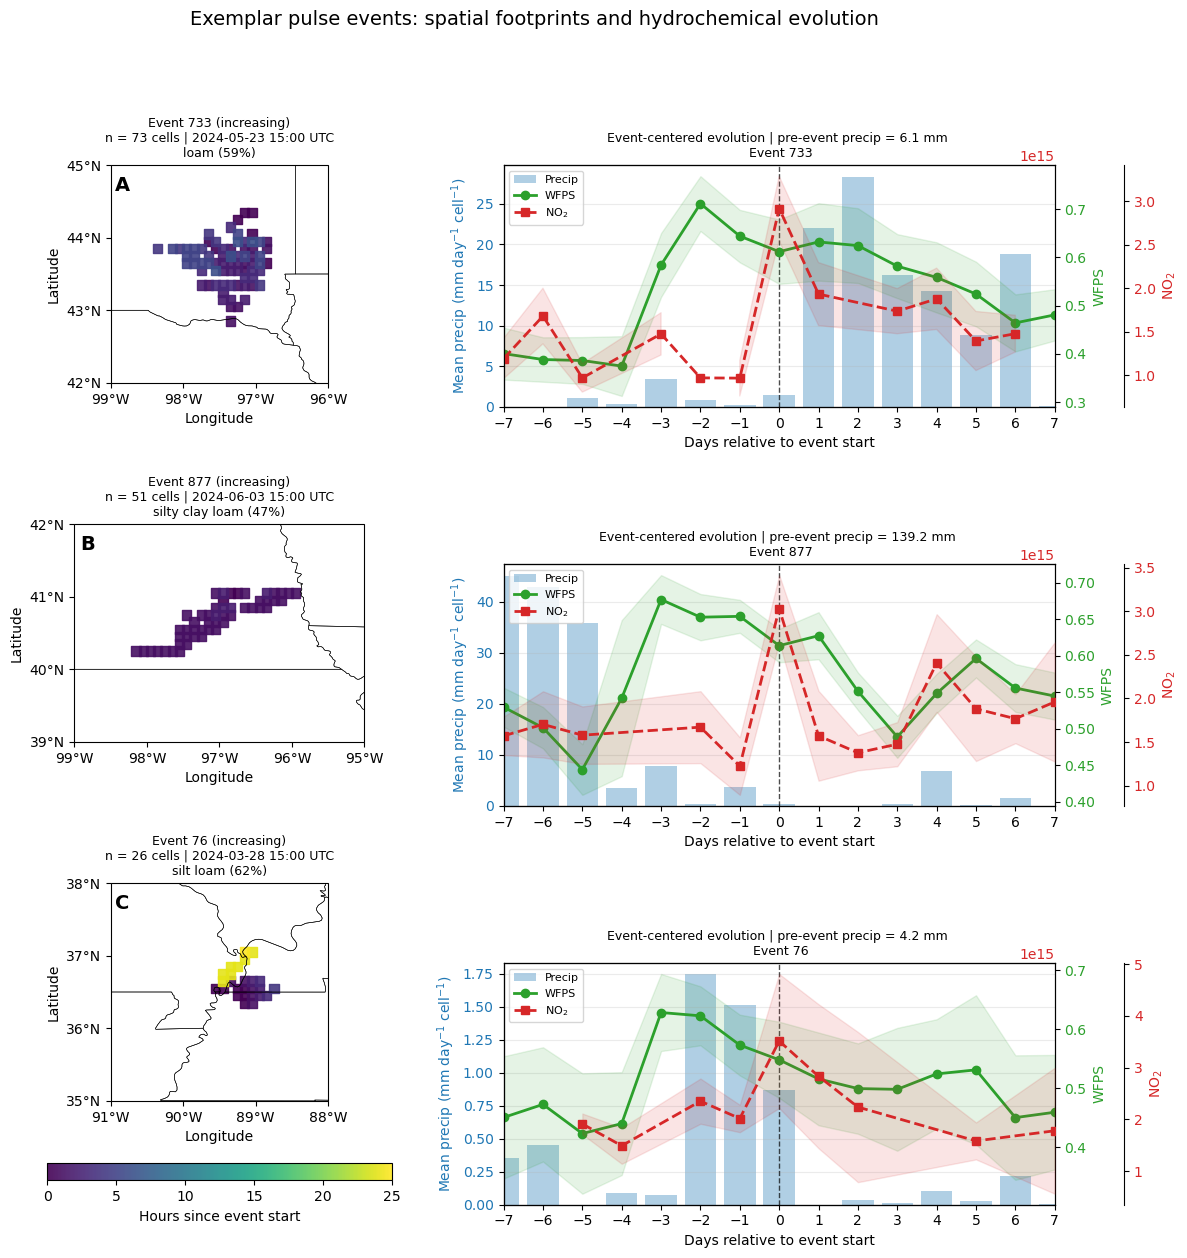

In [8]:

EXEMPLAR_EVENTS = [
    733,   # e.g. an increasing event ID
    877,   # e.g. a decreasing event ID
    76,   # e.g. a small or large group ID
]

pulse_df = groups_df.copy()
WINDOW_DAYS = 7

# --- validate ---
EXEMPLAR_EVENTS = [
    eid for eid in EXEMPLAR_EVENTS
    if eid is not None and eid in pulse_df["group_id"].unique()
]
assert len(EXEMPLAR_EVENTS) > 0, "Fill in at least one valid group_id above!"

n_events = len(EXEMPLAR_EVENTS)
panel_labels = list("ABCDEFGHIJKLMNOPQRSTUVWXYZ")

# global colour range
all_ep = pulse_df[pulse_df["group_id"].isin(EXEMPLAR_EVENTS)].copy()
all_ep["hours_since_start"] = (
    all_ep["datetime"]
    - all_ep.groupby("group_id")["datetime"].transform("min")
).dt.total_seconds() / 3600
vmin_time, vmax_time = 0, all_ep["hours_since_start"].max()

fig = plt.figure(figsize=(13, 4.5 * n_events))
outer = gridspec.GridSpec(n_events, 1, hspace=0.65)
map_axes, last_sc = [], None

for row, eid in enumerate(EXEMPLAR_EVENTS):
    inner = gridspec.GridSpecFromSubplotSpec(
        1, 2, subplot_spec=outer[row],
        width_ratios=[1.0, 1.6], wspace=0.25
    )

    event_pulses = pulse_df[pulse_df["group_id"] == eid].copy()
    event_cells  = event_pulses[["grid_lat", "grid_lon"]].drop_duplicates()
    if event_pulses.empty:
        continue

    t0 = event_pulses["datetime"].min()
    event_pulses["hours_since_start"] = (
        (event_pulses["datetime"] - t0).dt.total_seconds() / 3600
    )

    # soil texture label
    if "dominant_texture" in event_pulses.columns:
        es = (event_pulses[["grid_lat","grid_lon","dominant_texture"]]
              .drop_duplicates(subset=["grid_lat","grid_lon"])
              .dropna(subset=["dominant_texture"]))
        if len(es) > 0:
            sc_counts = es["dominant_texture"].value_counts()
            soil_str = f"{sc_counts.index[0]} ({sc_counts.iloc[0]/sc_counts.sum():.0%})"
        else:
            soil_str = "Soil texture unknown"
    else:
        soil_str = ""

    sm_label = event_pulses["sm_class"].iloc[0] if "sm_class" in event_pulses.columns else "Unknown"

    # ±7-day window from background df
    sub = df.merge(event_cells, on=["grid_lat","grid_lon"], how="inner").copy()
    sub = sub[
        (sub["datetime"] >= t0 - pd.Timedelta(days=WINDOW_DAYS)) &
        (sub["datetime"] <= t0 + pd.Timedelta(days=WINDOW_DAYS))
    ].copy()
    sub["lag_day"] = np.floor(
        (sub["datetime"] - t0).dt.total_seconds() / 86400.0
    ).astype(int)

    agg_cell = {"precip": ("h_precip_mm","sum"), "no2": ("no2_mean","mean")}
    if "WFPS_c" in sub.columns:
        agg_cell["wfps"] = ("WFPS_c","mean")
    cell_daily = sub.groupby(["grid_lat","grid_lon","lag_day"]).agg(**agg_cell).reset_index()

    agg_event = {
        "precip_mean": ("precip","mean"), "precip_std": ("precip","std"),
        "no2_mean":    ("no2","mean"),    "no2_std":    ("no2","std"),
    }
    if "wfps" in cell_daily.columns:
        agg_event["wfps_mean"] = ("wfps","mean")
        agg_event["wfps_std"]  = ("wfps","std")
    event_daily = cell_daily.groupby("lag_day").agg(**agg_event).reset_index()

    full_lags   = pd.DataFrame({"lag_day": np.arange(-WINDOW_DAYS, WINDOW_DAYS+1)})
    event_daily = full_lags.merge(event_daily, on="lag_day", how="left")
    event_daily[["precip_mean","precip_std"]] = event_daily[["precip_mean","precip_std"]].fillna(0)

    # ---- MAP ----
    ax_map = fig.add_subplot(inner[0], projection=ccrs.PlateCarree())
    map_axes.append(ax_map)
    lon_min = event_cells["grid_lon"].min()-0.5; lon_max = event_cells["grid_lon"].max()+0.5
    lat_min = event_cells["grid_lat"].min()-0.5; lat_max = event_cells["grid_lat"].max()+0.5
    ax_map.set_extent([lon_min,lon_max,lat_min,lat_max], crs=ccrs.PlateCarree())
    ax_map.add_feature(cfeature.STATES, linewidth=0.4)
    ax_map.add_feature(cfeature.BORDERS, linewidth=0.3)
    ax_map.coastlines(linewidth=0.3)
    sc = ax_map.scatter(
        event_pulses["grid_lon"], event_pulses["grid_lat"],
        c=event_pulses["hours_since_start"], cmap="viridis",
        vmin=vmin_time, vmax=vmax_time,
        s=45, marker="s", alpha=0.9, transform=ccrs.PlateCarree()
    )
    last_sc = sc
    ax_map.set_xticks(np.arange(np.floor(lon_min), np.ceil(lon_max)+1, 1), crs=ccrs.PlateCarree())
    ax_map.set_yticks(np.arange(np.floor(lat_min), np.ceil(lat_max)+1, 1), crs=ccrs.PlateCarree())
    ax_map.xaxis.set_major_formatter(cticker.LongitudeFormatter())
    ax_map.yaxis.set_major_formatter(cticker.LatitudeFormatter())
    ax_map.set_xlabel("Longitude"); ax_map.set_ylabel("Latitude")
    ax_map.text(0.02,0.95, panel_labels[row], transform=ax_map.transAxes,
                fontsize=14, fontweight="bold", va="top", ha="left")
    ax_map.set_title(
        f"Event {eid} ({sm_label})\n"
        f"n = {len(event_cells)} cells | {t0:%Y-%m-%d %H:%M} UTC"
        + (f"\n{soil_str}" if soil_str else ""),
        fontsize=9
    )

    # ---- TIME SERIES ----
    ax_ts = fig.add_subplot(inner[1])
    ax_ts.bar(event_daily["lag_day"], event_daily["precip_mean"],
              color="tab:blue", alpha=0.35, width=0.8, label="Precip")
    ax_ts.set_ylabel("Mean precip (mm day$^{-1}$ cell$^{-1}$)", color="tab:blue")
    ax_ts.tick_params(axis="y", labelcolor="tab:blue")
    ax_ts.axvline(0, color="k", linestyle="--", linewidth=1, alpha=0.7)
    ax_ts.grid(True, axis="y", alpha=0.25)

    has_wfps = "wfps_mean" in event_daily.columns
    if has_wfps:
        ax_wfps = ax_ts.twinx()
        vm = event_daily["wfps_mean"].notna()
        ax_wfps.plot(event_daily.loc[vm,"lag_day"], event_daily.loc[vm,"wfps_mean"],
                     color="tab:green", marker="o", linewidth=2, label="WFPS")
        ax_wfps.fill_between(
            event_daily.loc[vm,"lag_day"],
            (event_daily["wfps_mean"]-event_daily["wfps_std"]).loc[vm],
            (event_daily["wfps_mean"]+event_daily["wfps_std"]).loc[vm],
            color="tab:green", alpha=0.12
        )
        ax_wfps.set_ylabel("WFPS", color="tab:green")
        ax_wfps.tick_params(axis="y", labelcolor="tab:green")

    ax_no2 = ax_ts.twinx()
    if has_wfps:
        ax_no2.spines["right"].set_position(("outward", 50))
    vn = event_daily["no2_mean"].notna()
    ax_no2.plot(event_daily.loc[vn,"lag_day"], event_daily.loc[vn,"no2_mean"],
                color="tab:red", linestyle="--", marker="s", linewidth=2, label="NO$_2$")
    ax_no2.fill_between(
        event_daily.loc[vn,"lag_day"],
        (event_daily["no2_mean"]-event_daily["no2_std"]).loc[vn],
        (event_daily["no2_mean"]+event_daily["no2_std"]).loc[vn],
        color="tab:red", alpha=0.12
    )
    ax_no2.set_ylabel("NO$_2$", color="tab:red")
    ax_no2.tick_params(axis="y", labelcolor="tab:red")

    ax_ts.set_xlim(-WINDOW_DAYS, WINDOW_DAYS)
    ax_ts.set_xticks(np.arange(-WINDOW_DAYS, WINDOW_DAYS+1, 1))
    ax_ts.set_xlabel("Days relative to event start")
    pre_precip = event_daily.loc[event_daily["lag_day"] < 0, "precip_mean"].sum()
    ax_ts.set_title(f"Event-centered evolution | pre-event precip = {pre_precip:.1f} mm \n Event {eid}", fontsize=9)

    handles = [
        Patch(facecolor="tab:blue", alpha=0.35, label="Precip"),
        Line2D([0],[0], color="tab:red", linestyle="--", marker="s", linewidth=2, label="NO$_2$"),
    ]
    if has_wfps:
        handles.insert(1, Line2D([0],[0], color="tab:green", marker="o", linewidth=2, label="WFPS"))
    ax_ts.legend(handles=handles, fontsize=8, loc="upper left", frameon=True)

# shared colorbar
if last_sc is not None:
    cbar = fig.colorbar(last_sc, ax=map_axes, orientation="horizontal", fraction=0.04, pad=0.06)
    cbar.set_label("Hours since event start")

fig.suptitle("Exemplar pulse events: spatial footprints and hydrochemical evolution",
             fontsize=14, y=0.995)
plt.tight_layout(rect=[0,0.02,1,0.99])
plt.savefig("exemplar_events_chosen.png", dpi=150, bbox_inches="tight")
plt.show()

# plotting all of the increasing cases

/tmp/ipykernel_2072574/3160335005.py:178: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0,0.02,1,0.99])


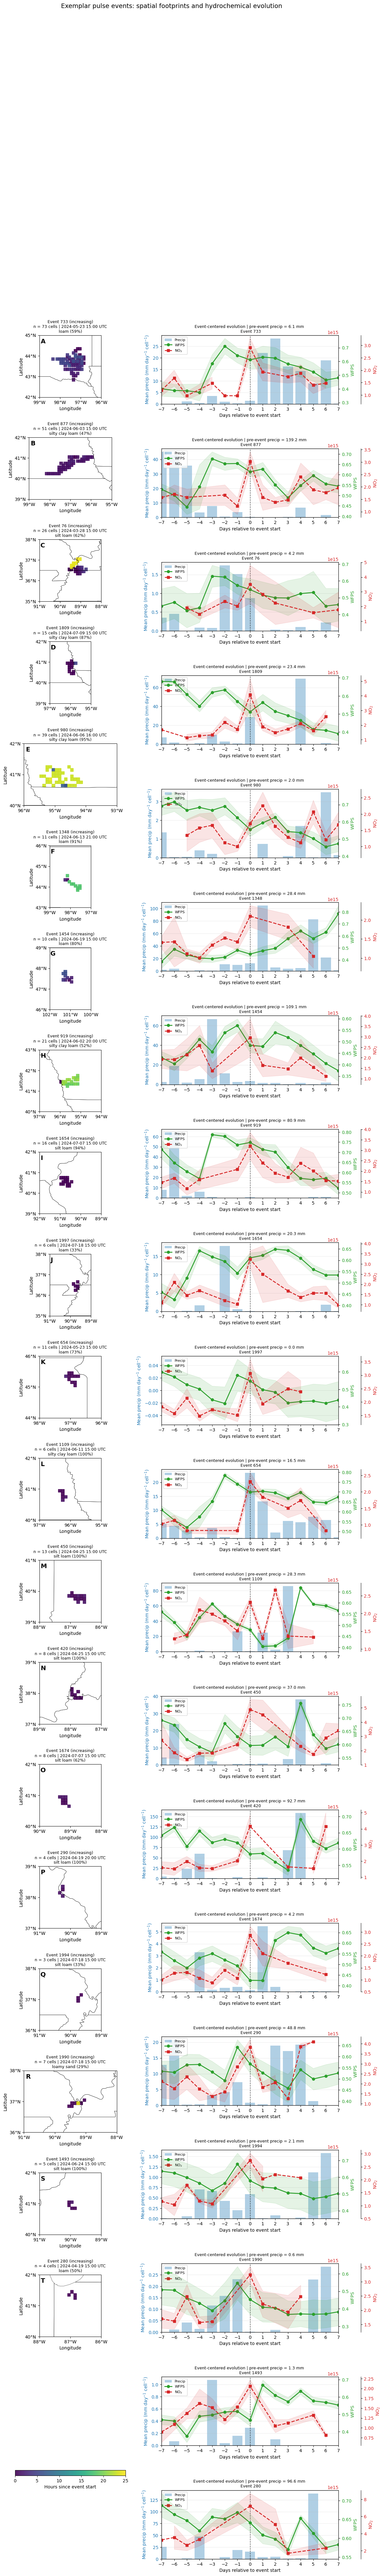

In [10]:
EXEMPLAR_EVENTS = [733, 877, 76, 1809, 980, 1348, 1454, 919, 1654, 1997, 654, 1109, 450, 420, 1674, 290, 1994, 1990, 1493, 280]

pulse_df = groups_df.copy()
WINDOW_DAYS = 7

# --- validate ---
EXEMPLAR_EVENTS = [
    eid for eid in EXEMPLAR_EVENTS
    if eid is not None and eid in pulse_df["group_id"].unique()
]
assert len(EXEMPLAR_EVENTS) > 0, "Fill in at least one valid group_id above!"

n_events = len(EXEMPLAR_EVENTS)
panel_labels = list("ABCDEFGHIJKLMNOPQRSTUVWXYZ")

# global colour range
all_ep = pulse_df[pulse_df["group_id"].isin(EXEMPLAR_EVENTS)].copy()
all_ep["hours_since_start"] = (
    all_ep["datetime"]
    - all_ep.groupby("group_id")["datetime"].transform("min")
).dt.total_seconds() / 3600
vmin_time, vmax_time = 0, all_ep["hours_since_start"].max()

fig = plt.figure(figsize=(13, 4.5 * n_events))
outer = gridspec.GridSpec(n_events, 1, hspace=0.65)
map_axes, last_sc = [], None

for row, eid in enumerate(EXEMPLAR_EVENTS):
    inner = gridspec.GridSpecFromSubplotSpec(
        1, 2, subplot_spec=outer[row],
        width_ratios=[1.0, 1.6], wspace=0.25
    )

    event_pulses = pulse_df[pulse_df["group_id"] == eid].copy()
    event_cells  = event_pulses[["grid_lat", "grid_lon"]].drop_duplicates()
    if event_pulses.empty:
        continue

    t0 = event_pulses["datetime"].min()
    event_pulses["hours_since_start"] = (
        (event_pulses["datetime"] - t0).dt.total_seconds() / 3600
    )

    # soil texture label
    if "dominant_texture" in event_pulses.columns:
        es = (event_pulses[["grid_lat","grid_lon","dominant_texture"]]
              .drop_duplicates(subset=["grid_lat","grid_lon"])
              .dropna(subset=["dominant_texture"]))
        if len(es) > 0:
            sc_counts = es["dominant_texture"].value_counts()
            soil_str = f"{sc_counts.index[0]} ({sc_counts.iloc[0]/sc_counts.sum():.0%})"
        else:
            soil_str = "Soil texture unknown"
    else:
        soil_str = ""

    sm_label = event_pulses["sm_class"].iloc[0] if "sm_class" in event_pulses.columns else "Unknown"

    # ±7-day window from background df
    sub = df.merge(event_cells, on=["grid_lat","grid_lon"], how="inner").copy()
    sub = sub[
        (sub["datetime"] >= t0 - pd.Timedelta(days=WINDOW_DAYS)) &
        (sub["datetime"] <= t0 + pd.Timedelta(days=WINDOW_DAYS))
    ].copy()
    sub["lag_day"] = np.floor(
        (sub["datetime"] - t0).dt.total_seconds() / 86400.0
    ).astype(int)

    agg_cell = {"precip": ("h_precip_mm","sum"), "no2": ("no2_mean","mean")}
    if "WFPS_c" in sub.columns:
        agg_cell["wfps"] = ("WFPS_c","mean")
    cell_daily = sub.groupby(["grid_lat","grid_lon","lag_day"]).agg(**agg_cell).reset_index()

    agg_event = {
        "precip_mean": ("precip","mean"), "precip_std": ("precip","std"),
        "no2_mean":    ("no2","mean"),    "no2_std":    ("no2","std"),
    }
    if "wfps" in cell_daily.columns:
        agg_event["wfps_mean"] = ("wfps","mean")
        agg_event["wfps_std"]  = ("wfps","std")
    event_daily = cell_daily.groupby("lag_day").agg(**agg_event).reset_index()

    full_lags   = pd.DataFrame({"lag_day": np.arange(-WINDOW_DAYS, WINDOW_DAYS+1)})
    event_daily = full_lags.merge(event_daily, on="lag_day", how="left")
    event_daily[["precip_mean","precip_std"]] = event_daily[["precip_mean","precip_std"]].fillna(0)

    # ---- MAP ----
    ax_map = fig.add_subplot(inner[0], projection=ccrs.PlateCarree())
    map_axes.append(ax_map)
    lon_min = event_cells["grid_lon"].min()-0.5; lon_max = event_cells["grid_lon"].max()+0.5
    lat_min = event_cells["grid_lat"].min()-0.5; lat_max = event_cells["grid_lat"].max()+0.5
    ax_map.set_extent([lon_min,lon_max,lat_min,lat_max], crs=ccrs.PlateCarree())
    ax_map.add_feature(cfeature.STATES, linewidth=0.4)
    ax_map.add_feature(cfeature.BORDERS, linewidth=0.3)
    ax_map.coastlines(linewidth=0.3)
    sc = ax_map.scatter(
        event_pulses["grid_lon"], event_pulses["grid_lat"],
        c=event_pulses["hours_since_start"], cmap="viridis",
        vmin=vmin_time, vmax=vmax_time,
        s=45, marker="s", alpha=0.9, transform=ccrs.PlateCarree()
    )
    last_sc = sc
    ax_map.set_xticks(np.arange(np.floor(lon_min), np.ceil(lon_max)+1, 1), crs=ccrs.PlateCarree())
    ax_map.set_yticks(np.arange(np.floor(lat_min), np.ceil(lat_max)+1, 1), crs=ccrs.PlateCarree())
    ax_map.xaxis.set_major_formatter(cticker.LongitudeFormatter())
    ax_map.yaxis.set_major_formatter(cticker.LatitudeFormatter())
    ax_map.set_xlabel("Longitude"); ax_map.set_ylabel("Latitude")
    ax_map.text(0.02,0.95, panel_labels[row], transform=ax_map.transAxes,
                fontsize=14, fontweight="bold", va="top", ha="left")
    ax_map.set_title(
        f"Event {eid} ({sm_label})\n"
        f"n = {len(event_cells)} cells | {t0:%Y-%m-%d %H:%M} UTC"
        + (f"\n{soil_str}" if soil_str else ""),
        fontsize=9
    )

    # ---- TIME SERIES ----
    ax_ts = fig.add_subplot(inner[1])
    ax_ts.bar(event_daily["lag_day"], event_daily["precip_mean"],
              color="tab:blue", alpha=0.35, width=0.8, label="Precip")
    ax_ts.set_ylabel("Mean precip (mm day$^{-1}$ cell$^{-1}$)", color="tab:blue")
    ax_ts.tick_params(axis="y", labelcolor="tab:blue")
    ax_ts.axvline(0, color="k", linestyle="--", linewidth=1, alpha=0.7)
    ax_ts.grid(True, axis="y", alpha=0.25)

    has_wfps = "wfps_mean" in event_daily.columns
    if has_wfps:
        ax_wfps = ax_ts.twinx()
        vm = event_daily["wfps_mean"].notna()
        ax_wfps.plot(event_daily.loc[vm,"lag_day"], event_daily.loc[vm,"wfps_mean"],
                     color="tab:green", marker="o", linewidth=2, label="WFPS")
        ax_wfps.fill_between(
            event_daily.loc[vm,"lag_day"],
            (event_daily["wfps_mean"]-event_daily["wfps_std"]).loc[vm],
            (event_daily["wfps_mean"]+event_daily["wfps_std"]).loc[vm],
            color="tab:green", alpha=0.12
        )
        ax_wfps.set_ylabel("WFPS", color="tab:green")
        ax_wfps.tick_params(axis="y", labelcolor="tab:green")

    ax_no2 = ax_ts.twinx()
    if has_wfps:
        ax_no2.spines["right"].set_position(("outward", 50))
    vn = event_daily["no2_mean"].notna()
    ax_no2.plot(event_daily.loc[vn,"lag_day"], event_daily.loc[vn,"no2_mean"],
                color="tab:red", linestyle="--", marker="s", linewidth=2, label="NO$_2$")
    ax_no2.fill_between(
        event_daily.loc[vn,"lag_day"],
        (event_daily["no2_mean"]-event_daily["no2_std"]).loc[vn],
        (event_daily["no2_mean"]+event_daily["no2_std"]).loc[vn],
        color="tab:red", alpha=0.12
    )
    ax_no2.set_ylabel("NO$_2$", color="tab:red")
    ax_no2.tick_params(axis="y", labelcolor="tab:red")

    ax_ts.set_xlim(-WINDOW_DAYS, WINDOW_DAYS)
    ax_ts.set_xticks(np.arange(-WINDOW_DAYS, WINDOW_DAYS+1, 1))
    ax_ts.set_xlabel("Days relative to event start")
    pre_precip = event_daily.loc[event_daily["lag_day"] < 0, "precip_mean"].sum()
    ax_ts.set_title(f"Event-centered evolution | pre-event precip = {pre_precip:.1f} mm \n Event {eid}", fontsize=9)


    handles = [
        Patch(facecolor="tab:blue", alpha=0.35, label="Precip"),
        Line2D([0],[0], color="tab:red", linestyle="--", marker="s", linewidth=2, label="NO$_2$"),
    ]
    if has_wfps:
        handles.insert(1, Line2D([0],[0], color="tab:green", marker="o", linewidth=2, label="WFPS"))
    ax_ts.legend(handles=handles, fontsize=8, loc="upper left", frameon=True)

# shared colorbar
if last_sc is not None:
    cbar = fig.colorbar(last_sc, ax=map_axes, orientation="horizontal", fraction=0.04, pad=0.06)
    cbar.set_label("Hours since event start")

fig.suptitle("Exemplar pulse events: spatial footprints and hydrochemical evolution",
             fontsize=14, y=0.995)
plt.tight_layout(rect=[0,0.02,1,0.99])
plt.savefig("exemplar_events_chosen.png", dpi=150, bbox_inches="tight")
plt.show()

# plotting all decreasing cases 

/tmp/ipykernel_2072574/300356943.py:177: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0,0.02,1,0.99])


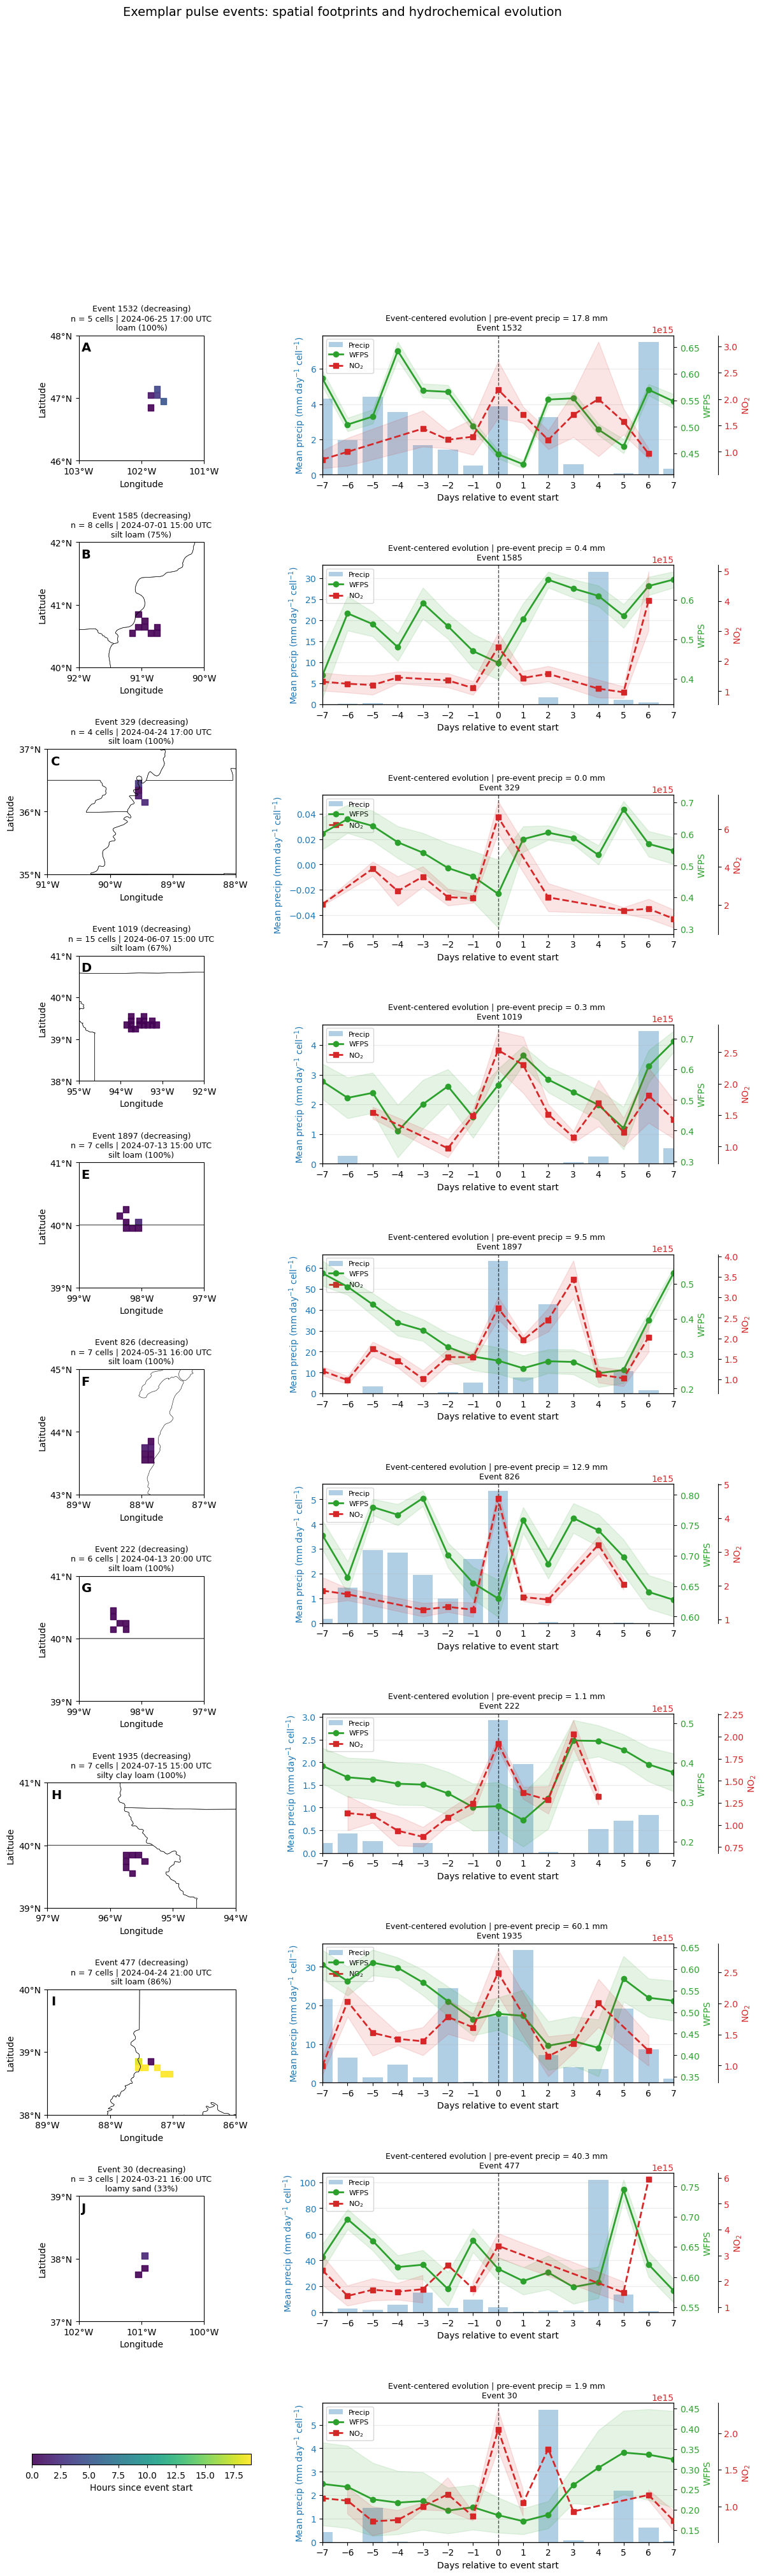

In [11]:
EXEMPLAR_EVENTS = [1532, 1585, 329, 1019, 1897, 826, 222, 1935, 477, 30]

pulse_df = groups_df.copy()
WINDOW_DAYS = 7

# --- validate ---
EXEMPLAR_EVENTS = [
    eid for eid in EXEMPLAR_EVENTS
    if eid is not None and eid in pulse_df["group_id"].unique()
]
assert len(EXEMPLAR_EVENTS) > 0, "Fill in at least one valid group_id above!"

n_events = len(EXEMPLAR_EVENTS)
panel_labels = list("ABCDEFGHIJKLMNOPQRSTUVWXYZ")

# global colour range
all_ep = pulse_df[pulse_df["group_id"].isin(EXEMPLAR_EVENTS)].copy()
all_ep["hours_since_start"] = (
    all_ep["datetime"]
    - all_ep.groupby("group_id")["datetime"].transform("min")
).dt.total_seconds() / 3600
vmin_time, vmax_time = 0, all_ep["hours_since_start"].max()

fig = plt.figure(figsize=(13, 4.5 * n_events))
outer = gridspec.GridSpec(n_events, 1, hspace=0.65)
map_axes, last_sc = [], None

for row, eid in enumerate(EXEMPLAR_EVENTS):
    inner = gridspec.GridSpecFromSubplotSpec(
        1, 2, subplot_spec=outer[row],
        width_ratios=[1.0, 1.6], wspace=0.25
    )

    event_pulses = pulse_df[pulse_df["group_id"] == eid].copy()
    event_cells  = event_pulses[["grid_lat", "grid_lon"]].drop_duplicates()
    if event_pulses.empty:
        continue

    t0 = event_pulses["datetime"].min()
    event_pulses["hours_since_start"] = (
        (event_pulses["datetime"] - t0).dt.total_seconds() / 3600
    )

    # soil texture label
    if "dominant_texture" in event_pulses.columns:
        es = (event_pulses[["grid_lat","grid_lon","dominant_texture"]]
              .drop_duplicates(subset=["grid_lat","grid_lon"])
              .dropna(subset=["dominant_texture"]))
        if len(es) > 0:
            sc_counts = es["dominant_texture"].value_counts()
            soil_str = f"{sc_counts.index[0]} ({sc_counts.iloc[0]/sc_counts.sum():.0%})"
        else:
            soil_str = "Soil texture unknown"
    else:
        soil_str = ""

    sm_label = event_pulses["sm_class"].iloc[0] if "sm_class" in event_pulses.columns else "Unknown"

    # ±7-day window from background df
    sub = df.merge(event_cells, on=["grid_lat","grid_lon"], how="inner").copy()
    sub = sub[
        (sub["datetime"] >= t0 - pd.Timedelta(days=WINDOW_DAYS)) &
        (sub["datetime"] <= t0 + pd.Timedelta(days=WINDOW_DAYS))
    ].copy()
    sub["lag_day"] = np.floor(
        (sub["datetime"] - t0).dt.total_seconds() / 86400.0
    ).astype(int)

    agg_cell = {"precip": ("h_precip_mm","sum"), "no2": ("no2_mean","mean")}
    if "WFPS_c" in sub.columns:
        agg_cell["wfps"] = ("WFPS_c","mean")
    cell_daily = sub.groupby(["grid_lat","grid_lon","lag_day"]).agg(**agg_cell).reset_index()

    agg_event = {
        "precip_mean": ("precip","mean"), "precip_std": ("precip","std"),
        "no2_mean":    ("no2","mean"),    "no2_std":    ("no2","std"),
    }
    if "wfps" in cell_daily.columns:
        agg_event["wfps_mean"] = ("wfps","mean")
        agg_event["wfps_std"]  = ("wfps","std")
    event_daily = cell_daily.groupby("lag_day").agg(**agg_event).reset_index()

    full_lags   = pd.DataFrame({"lag_day": np.arange(-WINDOW_DAYS, WINDOW_DAYS+1)})
    event_daily = full_lags.merge(event_daily, on="lag_day", how="left")
    event_daily[["precip_mean","precip_std"]] = event_daily[["precip_mean","precip_std"]].fillna(0)

    # ---- MAP ----
    ax_map = fig.add_subplot(inner[0], projection=ccrs.PlateCarree())
    map_axes.append(ax_map)
    lon_min = event_cells["grid_lon"].min()-0.5; lon_max = event_cells["grid_lon"].max()+0.5
    lat_min = event_cells["grid_lat"].min()-0.5; lat_max = event_cells["grid_lat"].max()+0.5
    ax_map.set_extent([lon_min,lon_max,lat_min,lat_max], crs=ccrs.PlateCarree())
    ax_map.add_feature(cfeature.STATES, linewidth=0.4)
    ax_map.add_feature(cfeature.BORDERS, linewidth=0.3)
    ax_map.coastlines(linewidth=0.3)
    sc = ax_map.scatter(
        event_pulses["grid_lon"], event_pulses["grid_lat"],
        c=event_pulses["hours_since_start"], cmap="viridis",
        vmin=vmin_time, vmax=vmax_time,
        s=45, marker="s", alpha=0.9, transform=ccrs.PlateCarree()
    )
    last_sc = sc
    ax_map.set_xticks(np.arange(np.floor(lon_min), np.ceil(lon_max)+1, 1), crs=ccrs.PlateCarree())
    ax_map.set_yticks(np.arange(np.floor(lat_min), np.ceil(lat_max)+1, 1), crs=ccrs.PlateCarree())
    ax_map.xaxis.set_major_formatter(cticker.LongitudeFormatter())
    ax_map.yaxis.set_major_formatter(cticker.LatitudeFormatter())
    ax_map.set_xlabel("Longitude"); ax_map.set_ylabel("Latitude")
    ax_map.text(0.02,0.95, panel_labels[row], transform=ax_map.transAxes,
                fontsize=14, fontweight="bold", va="top", ha="left")
    ax_map.set_title(
        f"Event {eid} ({sm_label})\n"
        f"n = {len(event_cells)} cells | {t0:%Y-%m-%d %H:%M} UTC"
        + (f"\n{soil_str}" if soil_str else ""),
        fontsize=9
    )

    # ---- TIME SERIES ----
    ax_ts = fig.add_subplot(inner[1])
    ax_ts.bar(event_daily["lag_day"], event_daily["precip_mean"],
              color="tab:blue", alpha=0.35, width=0.8, label="Precip")
    ax_ts.set_ylabel("Mean precip (mm day$^{-1}$ cell$^{-1}$)", color="tab:blue")
    ax_ts.tick_params(axis="y", labelcolor="tab:blue")
    ax_ts.axvline(0, color="k", linestyle="--", linewidth=1, alpha=0.7)
    ax_ts.grid(True, axis="y", alpha=0.25)

    has_wfps = "wfps_mean" in event_daily.columns
    if has_wfps:
        ax_wfps = ax_ts.twinx()
        vm = event_daily["wfps_mean"].notna()
        ax_wfps.plot(event_daily.loc[vm,"lag_day"], event_daily.loc[vm,"wfps_mean"],
                     color="tab:green", marker="o", linewidth=2, label="WFPS")
        ax_wfps.fill_between(
            event_daily.loc[vm,"lag_day"],
            (event_daily["wfps_mean"]-event_daily["wfps_std"]).loc[vm],
            (event_daily["wfps_mean"]+event_daily["wfps_std"]).loc[vm],
            color="tab:green", alpha=0.12
        )
        ax_wfps.set_ylabel("WFPS", color="tab:green")
        ax_wfps.tick_params(axis="y", labelcolor="tab:green")

    ax_no2 = ax_ts.twinx()
    if has_wfps:
        ax_no2.spines["right"].set_position(("outward", 50))
    vn = event_daily["no2_mean"].notna()
    ax_no2.plot(event_daily.loc[vn,"lag_day"], event_daily.loc[vn,"no2_mean"],
                color="tab:red", linestyle="--", marker="s", linewidth=2, label="NO$_2$")
    ax_no2.fill_between(
        event_daily.loc[vn,"lag_day"],
        (event_daily["no2_mean"]-event_daily["no2_std"]).loc[vn],
        (event_daily["no2_mean"]+event_daily["no2_std"]).loc[vn],
        color="tab:red", alpha=0.12
    )
    ax_no2.set_ylabel("NO$_2$", color="tab:red")
    ax_no2.tick_params(axis="y", labelcolor="tab:red")

    ax_ts.set_xlim(-WINDOW_DAYS, WINDOW_DAYS)
    ax_ts.set_xticks(np.arange(-WINDOW_DAYS, WINDOW_DAYS+1, 1))
    ax_ts.set_xlabel("Days relative to event start")
    pre_precip = event_daily.loc[event_daily["lag_day"] < 0, "precip_mean"].sum()
    ax_ts.set_title(f"Event-centered evolution | pre-event precip = {pre_precip:.1f} mm \n Event {eid}", fontsize=9)

    handles = [
        Patch(facecolor="tab:blue", alpha=0.35, label="Precip"),
        Line2D([0],[0], color="tab:red", linestyle="--", marker="s", linewidth=2, label="NO$_2$"),
    ]
    if has_wfps:
        handles.insert(1, Line2D([0],[0], color="tab:green", marker="o", linewidth=2, label="WFPS"))
    ax_ts.legend(handles=handles, fontsize=8, loc="upper left", frameon=True)

# shared colorbar
if last_sc is not None:
    cbar = fig.colorbar(last_sc, ax=map_axes, orientation="horizontal", fraction=0.04, pad=0.06)
    cbar.set_label("Hours since event start")

fig.suptitle("Exemplar pulse events: spatial footprints and hydrochemical evolution",
             fontsize=14, y=0.995)
plt.tight_layout(rect=[0,0.02,1,0.99])
plt.savefig("exemplar_events_chosen.png", dpi=150, bbox_inches="tight")
plt.show()

/tmp/ipykernel_2072574/536700276.py:178: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0,0.02,1,0.99])


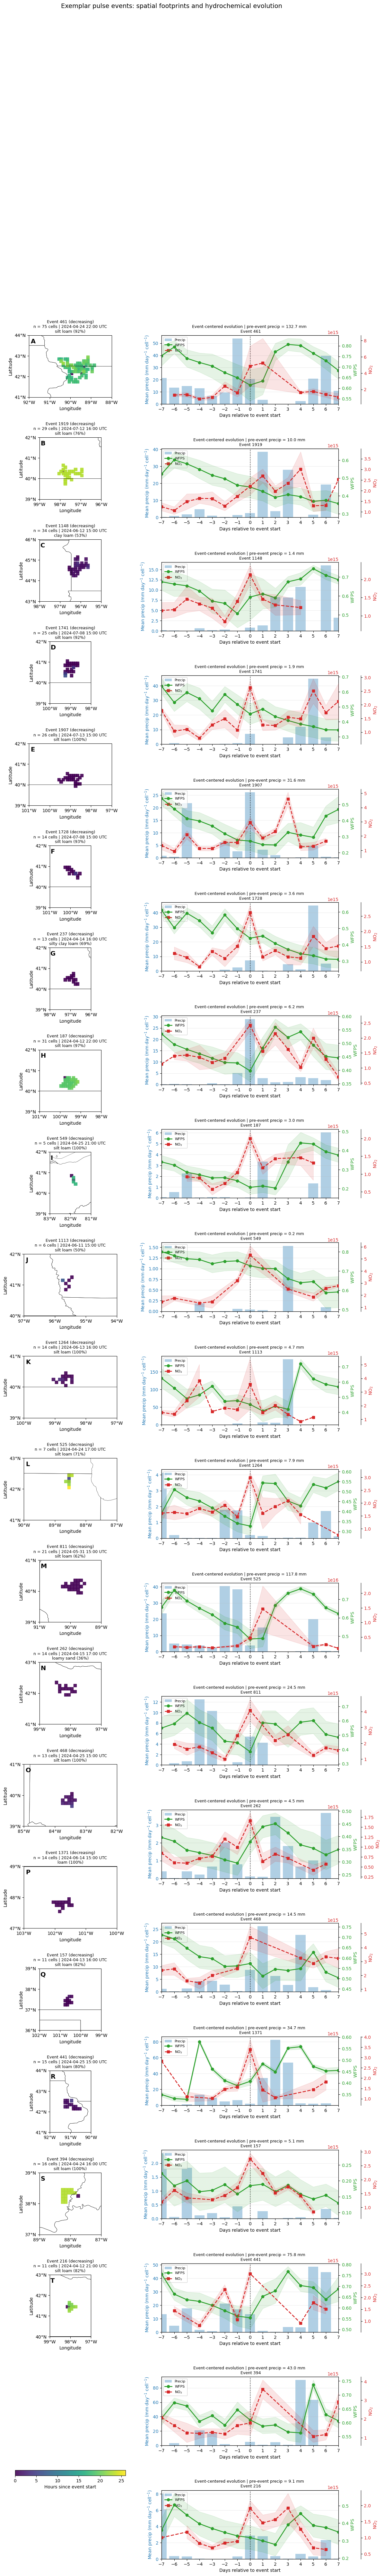

In [12]:
EXEMPLAR_EVENTS = [461, 1919, 1148, 1741, 1907, 1728, 237, 187, 549, 1113, 1264, 
                   525, 811, 262, 468, 1371, 157, 441, 394, 216]
  
pulse_df = groups_df.copy()
WINDOW_DAYS = 7

# --- validate ---
EXEMPLAR_EVENTS = [
    eid for eid in EXEMPLAR_EVENTS
    if eid is not None and eid in pulse_df["group_id"].unique()
]
assert len(EXEMPLAR_EVENTS) > 0, "Fill in at least one valid group_id above!"

n_events = len(EXEMPLAR_EVENTS)
panel_labels = list("ABCDEFGHIJKLMNOPQRSTUVWXYZ")

# global colour range
all_ep = pulse_df[pulse_df["group_id"].isin(EXEMPLAR_EVENTS)].copy()
all_ep["hours_since_start"] = (
    all_ep["datetime"]
    - all_ep.groupby("group_id")["datetime"].transform("min")
).dt.total_seconds() / 3600
vmin_time, vmax_time = 0, all_ep["hours_since_start"].max()

fig = plt.figure(figsize=(13, 4.5 * n_events))
outer = gridspec.GridSpec(n_events, 1, hspace=0.65)
map_axes, last_sc = [], None

for row, eid in enumerate(EXEMPLAR_EVENTS):
    inner = gridspec.GridSpecFromSubplotSpec(
        1, 2, subplot_spec=outer[row],
        width_ratios=[1.0, 1.6], wspace=0.25
    )

    event_pulses = pulse_df[pulse_df["group_id"] == eid].copy()
    event_cells  = event_pulses[["grid_lat", "grid_lon"]].drop_duplicates()
    if event_pulses.empty:
        continue

    t0 = event_pulses["datetime"].min()
    event_pulses["hours_since_start"] = (
        (event_pulses["datetime"] - t0).dt.total_seconds() / 3600
    )

    # soil texture label
    if "dominant_texture" in event_pulses.columns:
        es = (event_pulses[["grid_lat","grid_lon","dominant_texture"]]
              .drop_duplicates(subset=["grid_lat","grid_lon"])
              .dropna(subset=["dominant_texture"]))
        if len(es) > 0:
            sc_counts = es["dominant_texture"].value_counts()
            soil_str = f"{sc_counts.index[0]} ({sc_counts.iloc[0]/sc_counts.sum():.0%})"
        else:
            soil_str = "Soil texture unknown"
    else:
        soil_str = ""

    sm_label = event_pulses["sm_class"].iloc[0] if "sm_class" in event_pulses.columns else "Unknown"

    # ±7-day window from background df
    sub = df.merge(event_cells, on=["grid_lat","grid_lon"], how="inner").copy()
    sub = sub[
        (sub["datetime"] >= t0 - pd.Timedelta(days=WINDOW_DAYS)) &
        (sub["datetime"] <= t0 + pd.Timedelta(days=WINDOW_DAYS))
    ].copy()
    sub["lag_day"] = np.floor(
        (sub["datetime"] - t0).dt.total_seconds() / 86400.0
    ).astype(int)

    agg_cell = {"precip": ("h_precip_mm","sum"), "no2": ("no2_mean","mean")}
    if "WFPS_c" in sub.columns:
        agg_cell["wfps"] = ("WFPS_c","mean")
    cell_daily = sub.groupby(["grid_lat","grid_lon","lag_day"]).agg(**agg_cell).reset_index()

    agg_event = {
        "precip_mean": ("precip","mean"), "precip_std": ("precip","std"),
        "no2_mean":    ("no2","mean"),    "no2_std":    ("no2","std"),
    }
    if "wfps" in cell_daily.columns:
        agg_event["wfps_mean"] = ("wfps","mean")
        agg_event["wfps_std"]  = ("wfps","std")
    event_daily = cell_daily.groupby("lag_day").agg(**agg_event).reset_index()

    full_lags   = pd.DataFrame({"lag_day": np.arange(-WINDOW_DAYS, WINDOW_DAYS+1)})
    event_daily = full_lags.merge(event_daily, on="lag_day", how="left")
    event_daily[["precip_mean","precip_std"]] = event_daily[["precip_mean","precip_std"]].fillna(0)

    # ---- MAP ----
    ax_map = fig.add_subplot(inner[0], projection=ccrs.PlateCarree())
    map_axes.append(ax_map)
    lon_min = event_cells["grid_lon"].min()-0.5; lon_max = event_cells["grid_lon"].max()+0.5
    lat_min = event_cells["grid_lat"].min()-0.5; lat_max = event_cells["grid_lat"].max()+0.5
    ax_map.set_extent([lon_min,lon_max,lat_min,lat_max], crs=ccrs.PlateCarree())
    ax_map.add_feature(cfeature.STATES, linewidth=0.4)
    ax_map.add_feature(cfeature.BORDERS, linewidth=0.3)
    ax_map.coastlines(linewidth=0.3)
    sc = ax_map.scatter(
        event_pulses["grid_lon"], event_pulses["grid_lat"],
        c=event_pulses["hours_since_start"], cmap="viridis",
        vmin=vmin_time, vmax=vmax_time,
        s=45, marker="s", alpha=0.9, transform=ccrs.PlateCarree()
    )
    last_sc = sc
    ax_map.set_xticks(np.arange(np.floor(lon_min), np.ceil(lon_max)+1, 1), crs=ccrs.PlateCarree())
    ax_map.set_yticks(np.arange(np.floor(lat_min), np.ceil(lat_max)+1, 1), crs=ccrs.PlateCarree())
    ax_map.xaxis.set_major_formatter(cticker.LongitudeFormatter())
    ax_map.yaxis.set_major_formatter(cticker.LatitudeFormatter())
    ax_map.set_xlabel("Longitude"); ax_map.set_ylabel("Latitude")
    ax_map.text(0.02,0.95, panel_labels[row], transform=ax_map.transAxes,
                fontsize=14, fontweight="bold", va="top", ha="left")
    ax_map.set_title(
        f"Event {eid} ({sm_label})\n"
        f"n = {len(event_cells)} cells | {t0:%Y-%m-%d %H:%M} UTC"
        + (f"\n{soil_str}" if soil_str else ""),
        fontsize=9
    )

    # ---- TIME SERIES ----
    ax_ts = fig.add_subplot(inner[1])
    ax_ts.bar(event_daily["lag_day"], event_daily["precip_mean"],
              color="tab:blue", alpha=0.35, width=0.8, label="Precip")
    ax_ts.set_ylabel("Mean precip (mm day$^{-1}$ cell$^{-1}$)", color="tab:blue")
    ax_ts.tick_params(axis="y", labelcolor="tab:blue")
    ax_ts.axvline(0, color="k", linestyle="--", linewidth=1, alpha=0.7)
    ax_ts.grid(True, axis="y", alpha=0.25)

    has_wfps = "wfps_mean" in event_daily.columns
    if has_wfps:
        ax_wfps = ax_ts.twinx()
        vm = event_daily["wfps_mean"].notna()
        ax_wfps.plot(event_daily.loc[vm,"lag_day"], event_daily.loc[vm,"wfps_mean"],
                     color="tab:green", marker="o", linewidth=2, label="WFPS")
        ax_wfps.fill_between(
            event_daily.loc[vm,"lag_day"],
            (event_daily["wfps_mean"]-event_daily["wfps_std"]).loc[vm],
            (event_daily["wfps_mean"]+event_daily["wfps_std"]).loc[vm],
            color="tab:green", alpha=0.12
        )
        ax_wfps.set_ylabel("WFPS", color="tab:green")
        ax_wfps.tick_params(axis="y", labelcolor="tab:green")

    ax_no2 = ax_ts.twinx()
    if has_wfps:
        ax_no2.spines["right"].set_position(("outward", 50))
    vn = event_daily["no2_mean"].notna()
    ax_no2.plot(event_daily.loc[vn,"lag_day"], event_daily.loc[vn,"no2_mean"],
                color="tab:red", linestyle="--", marker="s", linewidth=2, label="NO$_2$")
    ax_no2.fill_between(
        event_daily.loc[vn,"lag_day"],
        (event_daily["no2_mean"]-event_daily["no2_std"]).loc[vn],
        (event_daily["no2_mean"]+event_daily["no2_std"]).loc[vn],
        color="tab:red", alpha=0.12
    )
    ax_no2.set_ylabel("NO$_2$", color="tab:red")
    ax_no2.tick_params(axis="y", labelcolor="tab:red")

    ax_ts.set_xlim(-WINDOW_DAYS, WINDOW_DAYS)
    ax_ts.set_xticks(np.arange(-WINDOW_DAYS, WINDOW_DAYS+1, 1))
    ax_ts.set_xlabel("Days relative to event start")
    pre_precip = event_daily.loc[event_daily["lag_day"] < 0, "precip_mean"].sum()
    ax_ts.set_title(f"Event-centered evolution | pre-event precip = {pre_precip:.1f} mm \n Event {eid}", fontsize=9)

    handles = [
        Patch(facecolor="tab:blue", alpha=0.35, label="Precip"),
        Line2D([0],[0], color="tab:red", linestyle="--", marker="s", linewidth=2, label="NO$_2$"),
    ]
    if has_wfps:
        handles.insert(1, Line2D([0],[0], color="tab:green", marker="o", linewidth=2, label="WFPS"))
    ax_ts.legend(handles=handles, fontsize=8, loc="upper left", frameon=True)

# shared colorbar
if last_sc is not None:
    cbar = fig.colorbar(last_sc, ax=map_axes, orientation="horizontal", fraction=0.04, pad=0.06)
    cbar.set_label("Hours since event start")

fig.suptitle("Exemplar pulse events: spatial footprints and hydrochemical evolution",
             fontsize=14, y=0.995)
plt.tight_layout(rect=[0,0.02,1,0.99])
plt.savefig("exemplar_events_chosen.png", dpi=150, bbox_inches="tight")
plt.show()

potential final contenders 

increasing
* 2

decreasing 
* 216

# I think these are my final contenders: 

/tmp/ipykernel_2072574/509777827.py:177: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0,0.02,1,0.99])


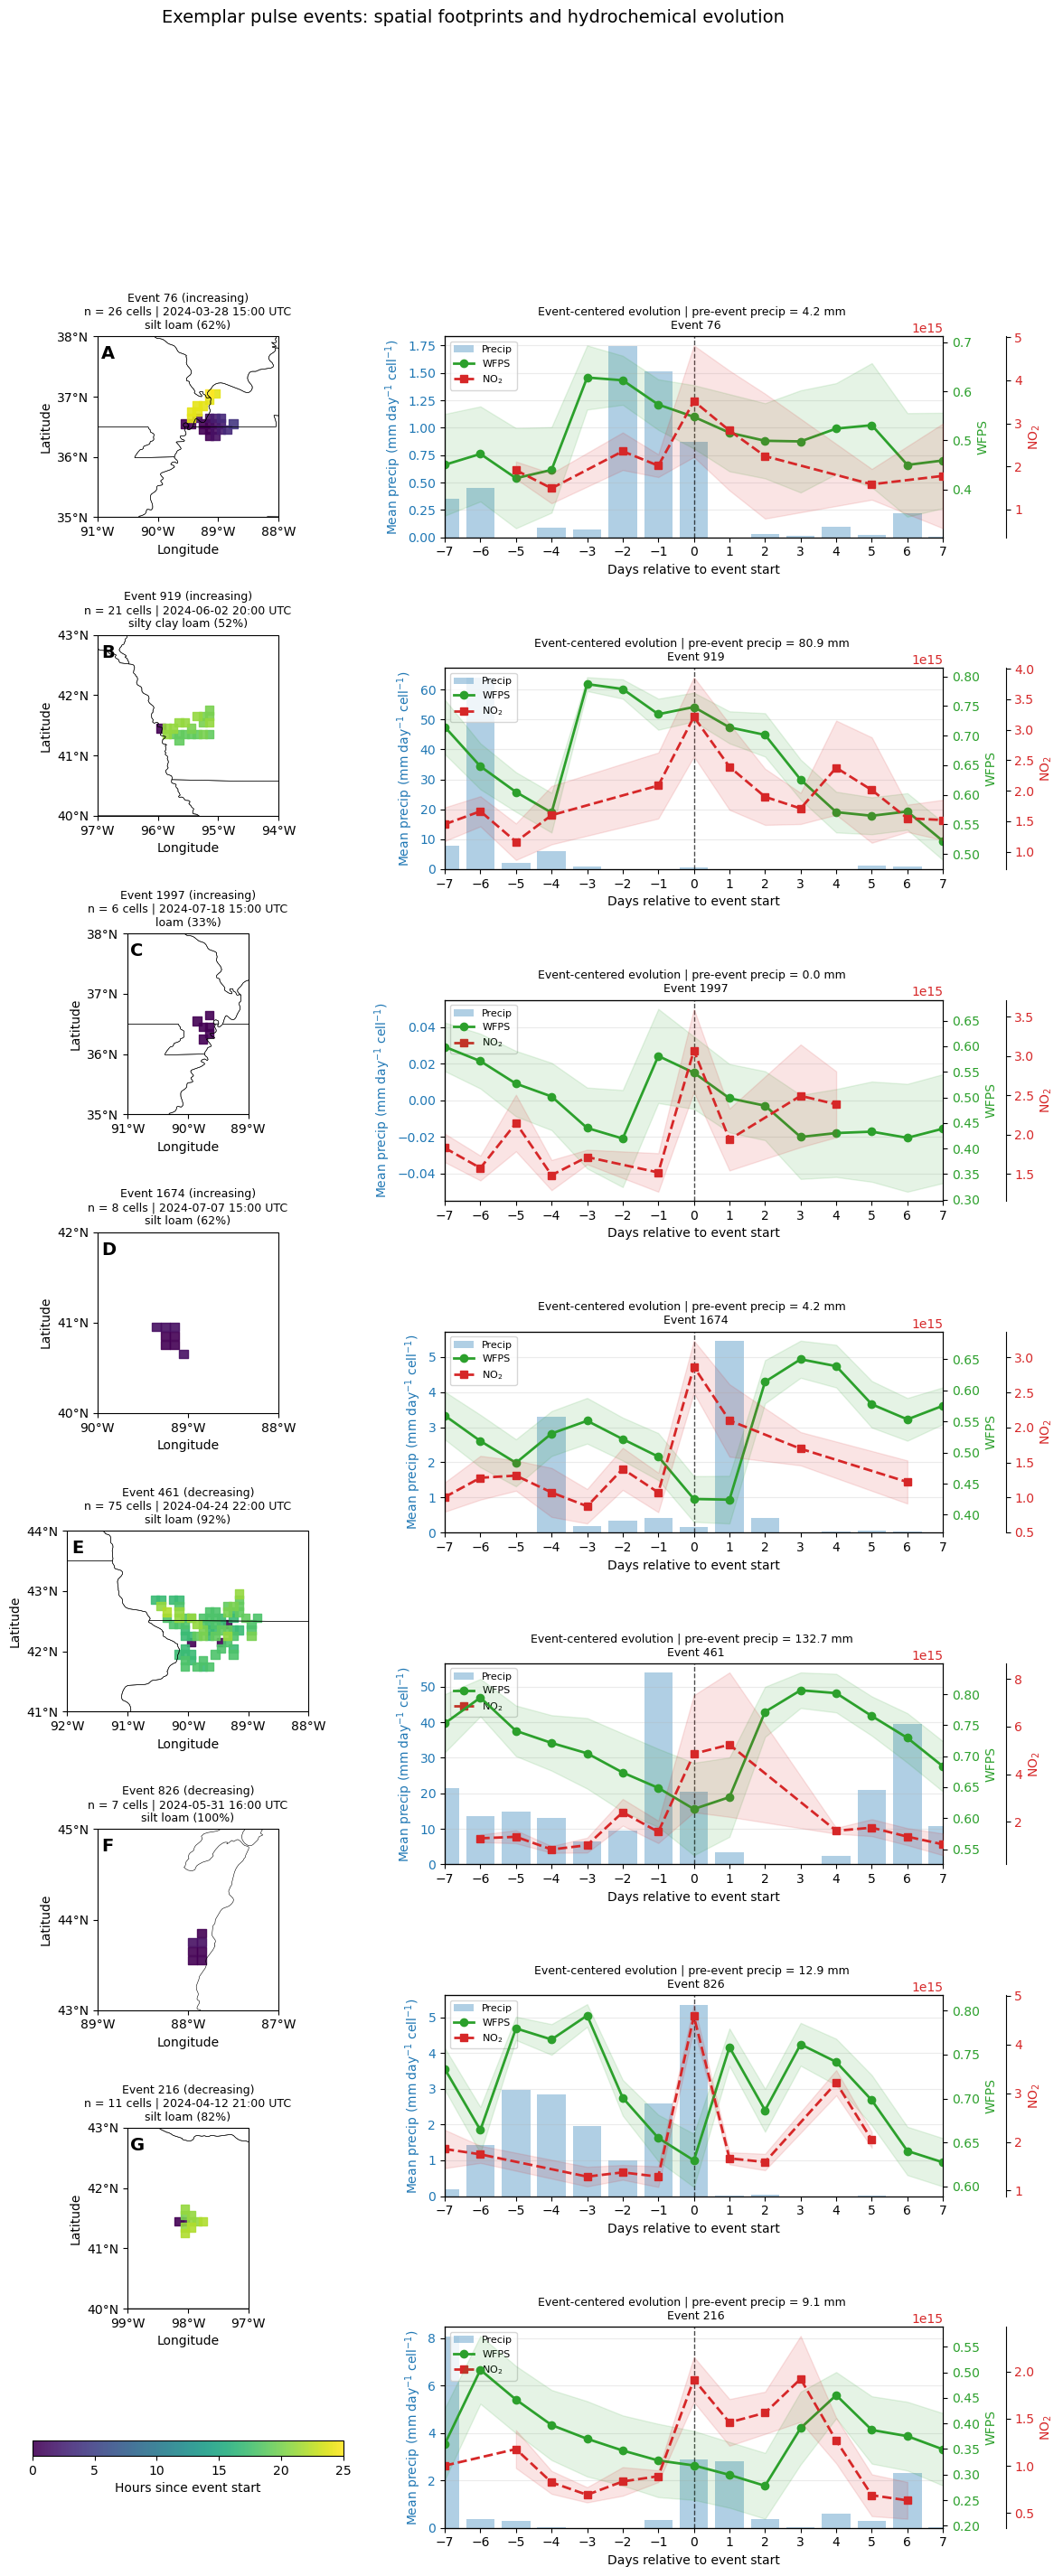

In [13]:

EXEMPLAR_EVENTS = [76, 919, 1997, 1674, 461, 826, 216 ]

pulse_df = groups_df.copy()
WINDOW_DAYS = 7

# --- validate ---
EXEMPLAR_EVENTS = [
    eid for eid in EXEMPLAR_EVENTS
    if eid is not None and eid in pulse_df["group_id"].unique()
]
assert len(EXEMPLAR_EVENTS) > 0, "Fill in at least one valid group_id above!"

n_events = len(EXEMPLAR_EVENTS)
panel_labels = list("ABCDEFGHIJKLMNOPQRSTUVWXYZ")

# global colour range
all_ep = pulse_df[pulse_df["group_id"].isin(EXEMPLAR_EVENTS)].copy()
all_ep["hours_since_start"] = (
    all_ep["datetime"]
    - all_ep.groupby("group_id")["datetime"].transform("min")
).dt.total_seconds() / 3600
vmin_time, vmax_time = 0, all_ep["hours_since_start"].max()

fig = plt.figure(figsize=(13, 4.5 * n_events))
outer = gridspec.GridSpec(n_events, 1, hspace=0.65)
map_axes, last_sc = [], None

for row, eid in enumerate(EXEMPLAR_EVENTS):
    inner = gridspec.GridSpecFromSubplotSpec(
        1, 2, subplot_spec=outer[row],
        width_ratios=[1.0, 1.6], wspace=0.25
    )

    event_pulses = pulse_df[pulse_df["group_id"] == eid].copy()
    event_cells  = event_pulses[["grid_lat", "grid_lon"]].drop_duplicates()
    if event_pulses.empty:
        continue

    t0 = event_pulses["datetime"].min()
    event_pulses["hours_since_start"] = (
        (event_pulses["datetime"] - t0).dt.total_seconds() / 3600
    )

    # soil texture label
    if "dominant_texture" in event_pulses.columns:
        es = (event_pulses[["grid_lat","grid_lon","dominant_texture"]]
              .drop_duplicates(subset=["grid_lat","grid_lon"])
              .dropna(subset=["dominant_texture"]))
        if len(es) > 0:
            sc_counts = es["dominant_texture"].value_counts()
            soil_str = f"{sc_counts.index[0]} ({sc_counts.iloc[0]/sc_counts.sum():.0%})"
        else:
            soil_str = "Soil texture unknown"
    else:
        soil_str = ""

    sm_label = event_pulses["sm_class"].iloc[0] if "sm_class" in event_pulses.columns else "Unknown"

    # ±7-day window from background df
    sub = df.merge(event_cells, on=["grid_lat","grid_lon"], how="inner").copy()
    sub = sub[
        (sub["datetime"] >= t0 - pd.Timedelta(days=WINDOW_DAYS)) &
        (sub["datetime"] <= t0 + pd.Timedelta(days=WINDOW_DAYS))
    ].copy()
    sub["lag_day"] = np.floor(
        (sub["datetime"] - t0).dt.total_seconds() / 86400.0
    ).astype(int)

    agg_cell = {"precip": ("h_precip_mm","sum"), "no2": ("no2_mean","mean")}
    if "WFPS_c" in sub.columns:
        agg_cell["wfps"] = ("WFPS_c","mean")
    cell_daily = sub.groupby(["grid_lat","grid_lon","lag_day"]).agg(**agg_cell).reset_index()

    agg_event = {
        "precip_mean": ("precip","mean"), "precip_std": ("precip","std"),
        "no2_mean":    ("no2","mean"),    "no2_std":    ("no2","std"),
    }
    if "wfps" in cell_daily.columns:
        agg_event["wfps_mean"] = ("wfps","mean")
        agg_event["wfps_std"]  = ("wfps","std")
    event_daily = cell_daily.groupby("lag_day").agg(**agg_event).reset_index()

    full_lags   = pd.DataFrame({"lag_day": np.arange(-WINDOW_DAYS, WINDOW_DAYS+1)})
    event_daily = full_lags.merge(event_daily, on="lag_day", how="left")
    event_daily[["precip_mean","precip_std"]] = event_daily[["precip_mean","precip_std"]].fillna(0)

    # ---- MAP ----
    ax_map = fig.add_subplot(inner[0], projection=ccrs.PlateCarree())
    map_axes.append(ax_map)
    lon_min = event_cells["grid_lon"].min()-0.5; lon_max = event_cells["grid_lon"].max()+0.5
    lat_min = event_cells["grid_lat"].min()-0.5; lat_max = event_cells["grid_lat"].max()+0.5
    ax_map.set_extent([lon_min,lon_max,lat_min,lat_max], crs=ccrs.PlateCarree())
    ax_map.add_feature(cfeature.STATES, linewidth=0.4)
    ax_map.add_feature(cfeature.BORDERS, linewidth=0.3)
    ax_map.coastlines(linewidth=0.3)
    sc = ax_map.scatter(
        event_pulses["grid_lon"], event_pulses["grid_lat"],
        c=event_pulses["hours_since_start"], cmap="viridis",
        vmin=vmin_time, vmax=vmax_time,
        s=45, marker="s", alpha=0.9, transform=ccrs.PlateCarree()
    )
    last_sc = sc
    ax_map.set_xticks(np.arange(np.floor(lon_min), np.ceil(lon_max)+1, 1), crs=ccrs.PlateCarree())
    ax_map.set_yticks(np.arange(np.floor(lat_min), np.ceil(lat_max)+1, 1), crs=ccrs.PlateCarree())
    ax_map.xaxis.set_major_formatter(cticker.LongitudeFormatter())
    ax_map.yaxis.set_major_formatter(cticker.LatitudeFormatter())
    ax_map.set_xlabel("Longitude"); ax_map.set_ylabel("Latitude")
    ax_map.text(0.02,0.95, panel_labels[row], transform=ax_map.transAxes,
                fontsize=14, fontweight="bold", va="top", ha="left")
    ax_map.set_title(
        f"Event {eid} ({sm_label})\n"
        f"n = {len(event_cells)} cells | {t0:%Y-%m-%d %H:%M} UTC"
        + (f"\n{soil_str}" if soil_str else ""),
        fontsize=9
    )

    # ---- TIME SERIES ----
    ax_ts = fig.add_subplot(inner[1])
    ax_ts.bar(event_daily["lag_day"], event_daily["precip_mean"],
              color="tab:blue", alpha=0.35, width=0.8, label="Precip")
    ax_ts.set_ylabel("Mean precip (mm day$^{-1}$ cell$^{-1}$)", color="tab:blue")
    ax_ts.tick_params(axis="y", labelcolor="tab:blue")
    ax_ts.axvline(0, color="k", linestyle="--", linewidth=1, alpha=0.7)
    ax_ts.grid(True, axis="y", alpha=0.25)

    has_wfps = "wfps_mean" in event_daily.columns
    if has_wfps:
        ax_wfps = ax_ts.twinx()
        vm = event_daily["wfps_mean"].notna()
        ax_wfps.plot(event_daily.loc[vm,"lag_day"], event_daily.loc[vm,"wfps_mean"],
                     color="tab:green", marker="o", linewidth=2, label="WFPS")
        ax_wfps.fill_between(
            event_daily.loc[vm,"lag_day"],
            (event_daily["wfps_mean"]-event_daily["wfps_std"]).loc[vm],
            (event_daily["wfps_mean"]+event_daily["wfps_std"]).loc[vm],
            color="tab:green", alpha=0.12
        )
        ax_wfps.set_ylabel("WFPS", color="tab:green")
        ax_wfps.tick_params(axis="y", labelcolor="tab:green")

    ax_no2 = ax_ts.twinx()
    if has_wfps:
        ax_no2.spines["right"].set_position(("outward", 50))
    vn = event_daily["no2_mean"].notna()
    ax_no2.plot(event_daily.loc[vn,"lag_day"], event_daily.loc[vn,"no2_mean"],
                color="tab:red", linestyle="--", marker="s", linewidth=2, label="NO$_2$")
    ax_no2.fill_between(
        event_daily.loc[vn,"lag_day"],
        (event_daily["no2_mean"]-event_daily["no2_std"]).loc[vn],
        (event_daily["no2_mean"]+event_daily["no2_std"]).loc[vn],
        color="tab:red", alpha=0.12
    )
    ax_no2.set_ylabel("NO$_2$", color="tab:red")
    ax_no2.tick_params(axis="y", labelcolor="tab:red")

    ax_ts.set_xlim(-WINDOW_DAYS, WINDOW_DAYS)
    ax_ts.set_xticks(np.arange(-WINDOW_DAYS, WINDOW_DAYS+1, 1))
    ax_ts.set_xlabel("Days relative to event start")
    pre_precip = event_daily.loc[event_daily["lag_day"] < 0, "precip_mean"].sum()
    ax_ts.set_title(f"Event-centered evolution | pre-event precip = {pre_precip:.1f} mm \n Event {eid}", fontsize=9)

    handles = [
        Patch(facecolor="tab:blue", alpha=0.35, label="Precip"),
        Line2D([0],[0], color="tab:red", linestyle="--", marker="s", linewidth=2, label="NO$_2$"),
    ]
    if has_wfps:
        handles.insert(1, Line2D([0],[0], color="tab:green", marker="o", linewidth=2, label="WFPS"))
    ax_ts.legend(handles=handles, fontsize=8, loc="upper left", frameon=True)

# shared colorbar
if last_sc is not None:
    cbar = fig.colorbar(last_sc, ax=map_axes, orientation="horizontal", fraction=0.04, pad=0.06)
    cbar.set_label("Hours since event start")

fig.suptitle("Exemplar pulse events: spatial footprints and hydrochemical evolution",
             fontsize=14, y=0.995)
plt.tight_layout(rect=[0,0.02,1,0.99])
plt.savefig("exemplar_events_chosen.png", dpi=150, bbox_inches="tight")
plt.show()

/tmp/ipykernel_2072574/1057640344.py:177: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0,0.02,1,0.99])


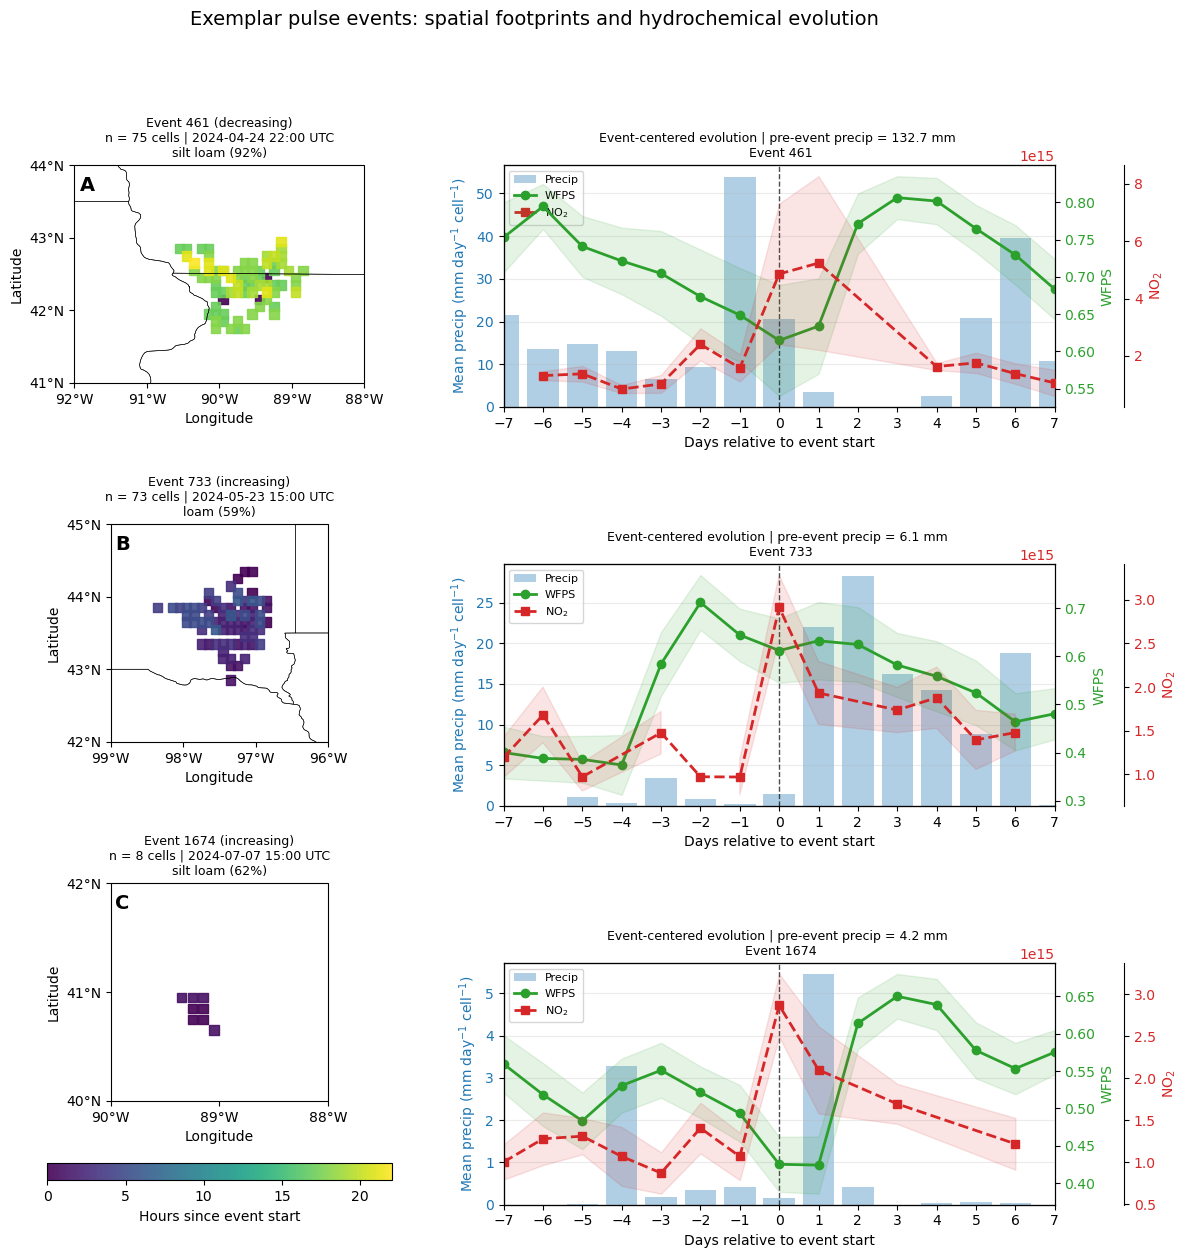

In [17]:

EXEMPLAR_EVENTS = [461, 733, 1674 ]

pulse_df = groups_df.copy()
WINDOW_DAYS = 7

# --- validate ---
EXEMPLAR_EVENTS = [
    eid for eid in EXEMPLAR_EVENTS
    if eid is not None and eid in pulse_df["group_id"].unique()
]
assert len(EXEMPLAR_EVENTS) > 0, "Fill in at least one valid group_id above!"

n_events = len(EXEMPLAR_EVENTS)
panel_labels = list("ABCDEFGHIJKLMNOPQRSTUVWXYZ")

# global colour range
all_ep = pulse_df[pulse_df["group_id"].isin(EXEMPLAR_EVENTS)].copy()
all_ep["hours_since_start"] = (
    all_ep["datetime"]
    - all_ep.groupby("group_id")["datetime"].transform("min")
).dt.total_seconds() / 3600
vmin_time, vmax_time = 0, all_ep["hours_since_start"].max()

fig = plt.figure(figsize=(13, 4.5 * n_events))
outer = gridspec.GridSpec(n_events, 1, hspace=0.65)
map_axes, last_sc = [], None

for row, eid in enumerate(EXEMPLAR_EVENTS):
    inner = gridspec.GridSpecFromSubplotSpec(
        1, 2, subplot_spec=outer[row],
        width_ratios=[1.0, 1.6], wspace=0.25
    )

    event_pulses = pulse_df[pulse_df["group_id"] == eid].copy()
    event_cells  = event_pulses[["grid_lat", "grid_lon"]].drop_duplicates()
    if event_pulses.empty:
        continue

    t0 = event_pulses["datetime"].min()
    event_pulses["hours_since_start"] = (
        (event_pulses["datetime"] - t0).dt.total_seconds() / 3600
    )

    # soil texture label
    if "dominant_texture" in event_pulses.columns:
        es = (event_pulses[["grid_lat","grid_lon","dominant_texture"]]
              .drop_duplicates(subset=["grid_lat","grid_lon"])
              .dropna(subset=["dominant_texture"]))
        if len(es) > 0:
            sc_counts = es["dominant_texture"].value_counts()
            soil_str = f"{sc_counts.index[0]} ({sc_counts.iloc[0]/sc_counts.sum():.0%})"
        else:
            soil_str = "Soil texture unknown"
    else:
        soil_str = ""

    sm_label = event_pulses["sm_class"].iloc[0] if "sm_class" in event_pulses.columns else "Unknown"

    # ±7-day window from background df
    sub = df.merge(event_cells, on=["grid_lat","grid_lon"], how="inner").copy()
    sub = sub[
        (sub["datetime"] >= t0 - pd.Timedelta(days=WINDOW_DAYS)) &
        (sub["datetime"] <= t0 + pd.Timedelta(days=WINDOW_DAYS))
    ].copy()
    sub["lag_day"] = np.floor(
        (sub["datetime"] - t0).dt.total_seconds() / 86400.0
    ).astype(int)

    agg_cell = {"precip": ("h_precip_mm","sum"), "no2": ("no2_mean","mean")}
    if "WFPS_c" in sub.columns:
        agg_cell["wfps"] = ("WFPS_c","mean")
    cell_daily = sub.groupby(["grid_lat","grid_lon","lag_day"]).agg(**agg_cell).reset_index()

    agg_event = {
        "precip_mean": ("precip","mean"), "precip_std": ("precip","std"),
        "no2_mean":    ("no2","mean"),    "no2_std":    ("no2","std"),
    }
    if "wfps" in cell_daily.columns:
        agg_event["wfps_mean"] = ("wfps","mean")
        agg_event["wfps_std"]  = ("wfps","std")
    event_daily = cell_daily.groupby("lag_day").agg(**agg_event).reset_index()

    full_lags   = pd.DataFrame({"lag_day": np.arange(-WINDOW_DAYS, WINDOW_DAYS+1)})
    event_daily = full_lags.merge(event_daily, on="lag_day", how="left")
    event_daily[["precip_mean","precip_std"]] = event_daily[["precip_mean","precip_std"]].fillna(0)

    # ---- MAP ----
    ax_map = fig.add_subplot(inner[0], projection=ccrs.PlateCarree())
    map_axes.append(ax_map)
    lon_min = event_cells["grid_lon"].min()-0.5; lon_max = event_cells["grid_lon"].max()+0.5
    lat_min = event_cells["grid_lat"].min()-0.5; lat_max = event_cells["grid_lat"].max()+0.5
    ax_map.set_extent([lon_min,lon_max,lat_min,lat_max], crs=ccrs.PlateCarree())
    ax_map.add_feature(cfeature.STATES, linewidth=0.4)
    ax_map.add_feature(cfeature.BORDERS, linewidth=0.3)
    ax_map.coastlines(linewidth=0.3)
    sc = ax_map.scatter(
        event_pulses["grid_lon"], event_pulses["grid_lat"],
        c=event_pulses["hours_since_start"], cmap="viridis",
        vmin=vmin_time, vmax=vmax_time,
        s=45, marker="s", alpha=0.9, transform=ccrs.PlateCarree()
    )
    last_sc = sc
    ax_map.set_xticks(np.arange(np.floor(lon_min), np.ceil(lon_max)+1, 1), crs=ccrs.PlateCarree())
    ax_map.set_yticks(np.arange(np.floor(lat_min), np.ceil(lat_max)+1, 1), crs=ccrs.PlateCarree())
    ax_map.xaxis.set_major_formatter(cticker.LongitudeFormatter())
    ax_map.yaxis.set_major_formatter(cticker.LatitudeFormatter())
    ax_map.set_xlabel("Longitude"); ax_map.set_ylabel("Latitude")
    ax_map.text(0.02,0.95, panel_labels[row], transform=ax_map.transAxes,
                fontsize=14, fontweight="bold", va="top", ha="left")
    ax_map.set_title(
        f"Event {eid} ({sm_label})\n"
        f"n = {len(event_cells)} cells | {t0:%Y-%m-%d %H:%M} UTC"
        + (f"\n{soil_str}" if soil_str else ""),
        fontsize=9
    )

    # ---- TIME SERIES ----
    ax_ts = fig.add_subplot(inner[1])
    ax_ts.bar(event_daily["lag_day"], event_daily["precip_mean"],
              color="tab:blue", alpha=0.35, width=0.8, label="Precip")
    ax_ts.set_ylabel("Mean precip (mm day$^{-1}$ cell$^{-1}$)", color="tab:blue")
    ax_ts.tick_params(axis="y", labelcolor="tab:blue")
    ax_ts.axvline(0, color="k", linestyle="--", linewidth=1, alpha=0.7)
    ax_ts.grid(True, axis="y", alpha=0.25)

    has_wfps = "wfps_mean" in event_daily.columns
    if has_wfps:
        ax_wfps = ax_ts.twinx()
        vm = event_daily["wfps_mean"].notna()
        ax_wfps.plot(event_daily.loc[vm,"lag_day"], event_daily.loc[vm,"wfps_mean"],
                     color="tab:green", marker="o", linewidth=2, label="WFPS")
        ax_wfps.fill_between(
            event_daily.loc[vm,"lag_day"],
            (event_daily["wfps_mean"]-event_daily["wfps_std"]).loc[vm],
            (event_daily["wfps_mean"]+event_daily["wfps_std"]).loc[vm],
            color="tab:green", alpha=0.12
        )
        ax_wfps.set_ylabel("WFPS", color="tab:green")
        ax_wfps.tick_params(axis="y", labelcolor="tab:green")

    ax_no2 = ax_ts.twinx()
    if has_wfps:
        ax_no2.spines["right"].set_position(("outward", 50))
    vn = event_daily["no2_mean"].notna()
    ax_no2.plot(event_daily.loc[vn,"lag_day"], event_daily.loc[vn,"no2_mean"],
                color="tab:red", linestyle="--", marker="s", linewidth=2, label="NO$_2$")
    ax_no2.fill_between(
        event_daily.loc[vn,"lag_day"],
        (event_daily["no2_mean"]-event_daily["no2_std"]).loc[vn],
        (event_daily["no2_mean"]+event_daily["no2_std"]).loc[vn],
        color="tab:red", alpha=0.12
    )
    ax_no2.set_ylabel("NO$_2$", color="tab:red")
    ax_no2.tick_params(axis="y", labelcolor="tab:red")

    ax_ts.set_xlim(-WINDOW_DAYS, WINDOW_DAYS)
    ax_ts.set_xticks(np.arange(-WINDOW_DAYS, WINDOW_DAYS+1, 1))
    ax_ts.set_xlabel("Days relative to event start")
    pre_precip = event_daily.loc[event_daily["lag_day"] < 0, "precip_mean"].sum()
    ax_ts.set_title(f"Event-centered evolution | pre-event precip = {pre_precip:.1f} mm \n Event {eid}", fontsize=9)

    handles = [
        Patch(facecolor="tab:blue", alpha=0.35, label="Precip"),
        Line2D([0],[0], color="tab:red", linestyle="--", marker="s", linewidth=2, label="NO$_2$"),
    ]
    if has_wfps:
        handles.insert(1, Line2D([0],[0], color="tab:green", marker="o", linewidth=2, label="WFPS"))
    ax_ts.legend(handles=handles, fontsize=8, loc="upper left", frameon=True)

# shared colorbar
if last_sc is not None:
    cbar = fig.colorbar(last_sc, ax=map_axes, orientation="horizontal", fraction=0.04, pad=0.06)
    cbar.set_label("Hours since event start")

fig.suptitle("Exemplar pulse events: spatial footprints and hydrochemical evolution",
             fontsize=14, y=0.995)
plt.tight_layout(rect=[0,0.02,1,0.99])
plt.savefig("exemplar_events_chosen.png", dpi=150, bbox_inches="tight")
plt.show()

# plotting hourly

/tmp/ipykernel_3303670/1586789215.py:190: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0,0.02,1,0.99])


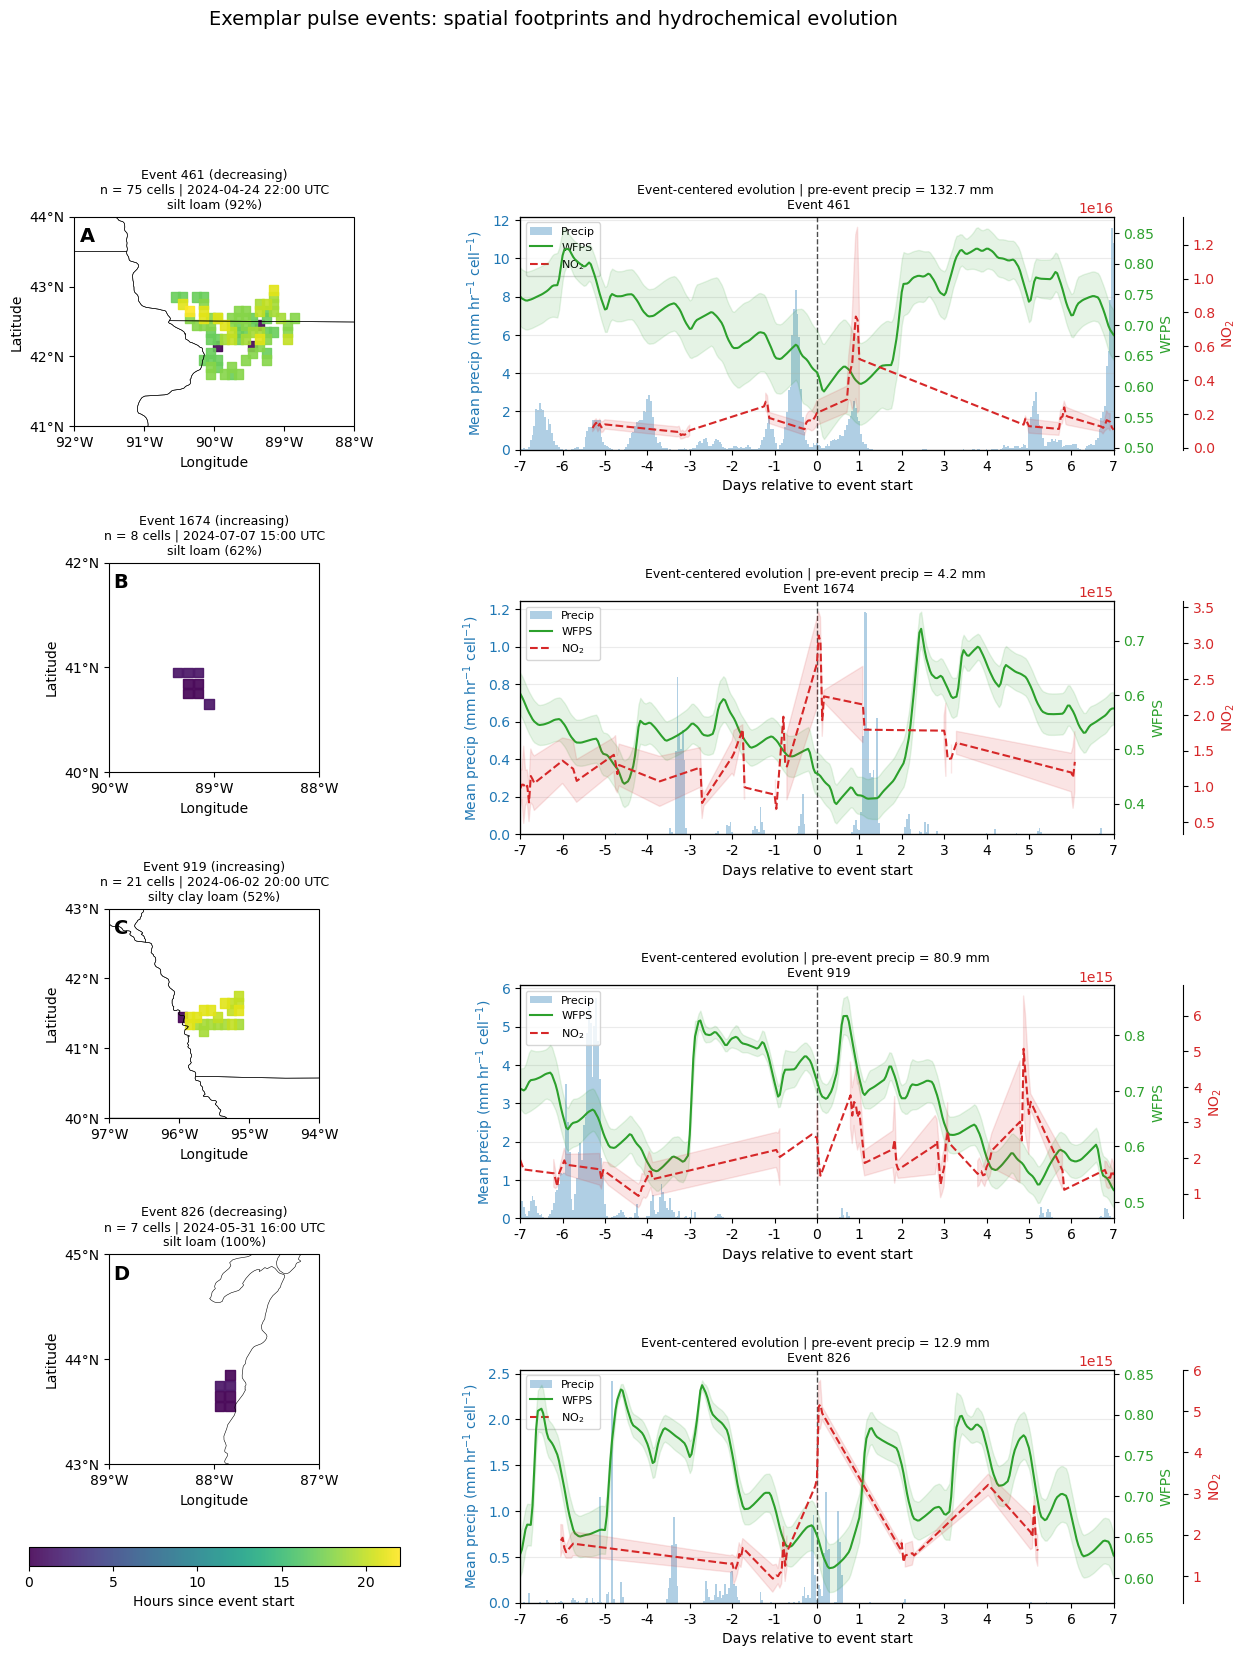

In [16]:
# -------------------------------------------------------
# >>> EDIT THESE 3 after running Cell 1 <
EXEMPLAR_EVENTS = [461, 1674, 919, 826]
# -------------------------------------------------------

pulse_df = groups_df.copy()
WINDOW_DAYS = 7
WINDOW_HOURS = WINDOW_DAYS * 24

EXEMPLAR_EVENTS = [
    eid for eid in EXEMPLAR_EVENTS
    if eid is not None and eid in pulse_df["group_id"].unique()
]
assert len(EXEMPLAR_EVENTS) > 0, "Fill in at least one valid group_id above!"

n_events = len(EXEMPLAR_EVENTS)
panel_labels = list("ABCDEFGHIJKLMNOPQRSTUVWXYZ")

# global colour range
all_ep = pulse_df[pulse_df["group_id"].isin(EXEMPLAR_EVENTS)].copy()
all_ep["hours_since_start"] = (
    all_ep["datetime"]
    - all_ep.groupby("group_id")["datetime"].transform("min")
).dt.total_seconds() / 3600
vmin_time, vmax_time = 0, all_ep["hours_since_start"].max()

fig = plt.figure(figsize=(14, 4.5 * n_events))
outer = gridspec.GridSpec(n_events, 1, hspace=0.65)
map_axes, last_sc = [], None

for row, eid in enumerate(EXEMPLAR_EVENTS):
    inner = gridspec.GridSpecFromSubplotSpec(
        1, 2, subplot_spec=outer[row],
        width_ratios=[1.0, 1.6], wspace=0.25
    )

    event_pulses = pulse_df[pulse_df["group_id"] == eid].copy()
    event_cells  = event_pulses[["grid_lat", "grid_lon"]].drop_duplicates()
    if event_pulses.empty:
        continue

    t0 = event_pulses["datetime"].min()
    event_pulses["hours_since_start"] = (
        (event_pulses["datetime"] - t0).dt.total_seconds() / 3600
    )

    # soil texture label
    if "dominant_texture" in event_pulses.columns:
        es = (event_pulses[["grid_lat","grid_lon","dominant_texture"]]
              .drop_duplicates(subset=["grid_lat","grid_lon"])
              .dropna(subset=["dominant_texture"]))
        if len(es) > 0:
            sc_counts = es["dominant_texture"].value_counts()
            soil_str = f"{sc_counts.index[0]} ({sc_counts.iloc[0]/sc_counts.sum():.0%})"
        else:
            soil_str = "Soil texture unknown"
    else:
        soil_str = ""

    sm_label = event_pulses["sm_class"].iloc[0] if "sm_class" in event_pulses.columns else "Unknown"

    # ±7-day window from background df, hourly
    sub = df.merge(event_cells, on=["grid_lat","grid_lon"], how="inner").copy()
    sub = sub[
        (sub["datetime"] >= t0 - pd.Timedelta(hours=WINDOW_HOURS)) &
        (sub["datetime"] <= t0 + pd.Timedelta(hours=WINDOW_HOURS))
    ].copy()

    # lag in hours (rounded to nearest hour)
    sub["lag_hour"] = np.round(
        (sub["datetime"] - t0).dt.total_seconds() / 3600.0
    ).astype(int)

    # aggregate per cell per hour
    agg_cell = {"precip": ("h_precip_mm", "sum"), "no2": ("no2_mean", "mean")}
    if "WFPS_c" in sub.columns:
        agg_cell["wfps"] = ("WFPS_c", "mean")
    cell_hourly = sub.groupby(["grid_lat","grid_lon","lag_hour"]).agg(**agg_cell).reset_index()

    # aggregate across event cells
    agg_event = {
        "precip_mean": ("precip","mean"), "precip_std": ("precip","std"),
        "no2_mean":    ("no2","mean"),    "no2_std":    ("no2","std"),
    }
    if "wfps" in cell_hourly.columns:
        agg_event["wfps_mean"] = ("wfps","mean")
        agg_event["wfps_std"]  = ("wfps","std")
    event_hourly = cell_hourly.groupby("lag_hour").agg(**agg_event).reset_index()

    # fill full hourly range
    full_hours   = pd.DataFrame({"lag_hour": np.arange(-WINDOW_HOURS, WINDOW_HOURS+1)})
    event_hourly = full_hours.merge(event_hourly, on="lag_hour", how="left")
    event_hourly[["precip_mean","precip_std"]] = event_hourly[["precip_mean","precip_std"]].fillna(0)

    # ---- MAP ----
    ax_map = fig.add_subplot(inner[0], projection=ccrs.PlateCarree())
    map_axes.append(ax_map)
    lon_min = event_cells["grid_lon"].min()-0.5; lon_max = event_cells["grid_lon"].max()+0.5
    lat_min = event_cells["grid_lat"].min()-0.5; lat_max = event_cells["grid_lat"].max()+0.5
    ax_map.set_extent([lon_min,lon_max,lat_min,lat_max], crs=ccrs.PlateCarree())
    ax_map.add_feature(cfeature.STATES, linewidth=0.4)
    ax_map.add_feature(cfeature.BORDERS, linewidth=0.3)
    ax_map.coastlines(linewidth=0.3)
    sc = ax_map.scatter(
        event_pulses["grid_lon"], event_pulses["grid_lat"],
        c=event_pulses["hours_since_start"], cmap="viridis",
        vmin=vmin_time, vmax=vmax_time,
        s=45, marker="s", alpha=0.9, transform=ccrs.PlateCarree()
    )
    last_sc = sc
    ax_map.set_xticks(np.arange(np.floor(lon_min), np.ceil(lon_max)+1, 1), crs=ccrs.PlateCarree())
    ax_map.set_yticks(np.arange(np.floor(lat_min), np.ceil(lat_max)+1, 1), crs=ccrs.PlateCarree())
    ax_map.xaxis.set_major_formatter(cticker.LongitudeFormatter())
    ax_map.yaxis.set_major_formatter(cticker.LatitudeFormatter())
    ax_map.set_xlabel("Longitude"); ax_map.set_ylabel("Latitude")
    ax_map.text(0.02, 0.95, panel_labels[row], transform=ax_map.transAxes,
                fontsize=14, fontweight="bold", va="top", ha="left")
    ax_map.set_title(
        f"Event {eid} ({sm_label})\n"
        f"n = {len(event_cells)} cells | {t0:%Y-%m-%d %H:%M} UTC"
        + (f"\n{soil_str}" if soil_str else ""),
        fontsize=9
    )

    # ---- TIME SERIES (hourly) ----
    ax_ts = fig.add_subplot(inner[1])
    ax_ts.bar(event_hourly["lag_hour"], event_hourly["precip_mean"],
              color="tab:blue", alpha=0.35, width=1.0, label="Precip")
    ax_ts.set_ylabel("Mean precip (mm hr$^{-1}$ cell$^{-1}$)", color="tab:blue")
    ax_ts.tick_params(axis="y", labelcolor="tab:blue")
    ax_ts.axvline(0, color="k", linestyle="--", linewidth=1, alpha=0.7)
    ax_ts.grid(True, axis="y", alpha=0.25)

    has_wfps = "wfps_mean" in event_hourly.columns
    if has_wfps:
        ax_wfps = ax_ts.twinx()
        vm = event_hourly["wfps_mean"].notna()
        ax_wfps.plot(event_hourly.loc[vm,"lag_hour"], event_hourly.loc[vm,"wfps_mean"],
                     color="tab:green", linewidth=1.5, label="WFPS")
        ax_wfps.fill_between(
            event_hourly.loc[vm,"lag_hour"],
            (event_hourly["wfps_mean"]-event_hourly["wfps_std"]).loc[vm],
            (event_hourly["wfps_mean"]+event_hourly["wfps_std"]).loc[vm],
            color="tab:green", alpha=0.12
        )
        ax_wfps.set_ylabel("WFPS", color="tab:green")
        ax_wfps.tick_params(axis="y", labelcolor="tab:green")

    ax_no2 = ax_ts.twinx()
    if has_wfps:
        ax_no2.spines["right"].set_position(("outward", 50))
    vn = event_hourly["no2_mean"].notna()
    ax_no2.plot(event_hourly.loc[vn,"lag_hour"], event_hourly.loc[vn,"no2_mean"],
                color="tab:red", linestyle="--", linewidth=1.5, label="NO$_2$")
    ax_no2.fill_between(
        event_hourly.loc[vn,"lag_hour"],
        (event_hourly["no2_mean"]-event_hourly["no2_std"]).loc[vn],
        (event_hourly["no2_mean"]+event_hourly["no2_std"]).loc[vn],
        color="tab:red", alpha=0.12
    )
    ax_no2.set_ylabel("NO$_2$", color="tab:red")
    ax_no2.tick_params(axis="y", labelcolor="tab:red")

    # x-axis: tick every 24 hrs, label as days
    ax_ts.set_xlim(-WINDOW_HOURS, WINDOW_HOURS)
    day_ticks = np.arange(-WINDOW_DAYS, WINDOW_DAYS+1) * 24
    ax_ts.set_xticks(day_ticks)
    ax_ts.set_xticklabels([str(d) for d in np.arange(-WINDOW_DAYS, WINDOW_DAYS+1)])
    ax_ts.set_xlabel("Days relative to event start")

    pre_precip = event_hourly.loc[event_hourly["lag_hour"] < 0, "precip_mean"].sum()
    ax_ts.set_title(f"Event-centered evolution | pre-event precip = {pre_precip:.1f} mm \n Event {eid}", fontsize=9)


    handles = [
        Patch(facecolor="tab:blue", alpha=0.35, label="Precip"),
        Line2D([0],[0], color="tab:red", linestyle="--", linewidth=1.5, label="NO$_2$"),
    ]
    if has_wfps:
        handles.insert(1, Line2D([0],[0], color="tab:green", linewidth=1.5, label="WFPS"))
    ax_ts.legend(handles=handles, fontsize=8, loc="upper left", frameon=True)

# shared colorbar
if last_sc is not None:
    cbar = fig.colorbar(last_sc, ax=map_axes, orientation="horizontal", fraction=0.04, pad=0.06)
    cbar.set_label("Hours since event start")

fig.suptitle("Exemplar pulse events: spatial footprints and hydrochemical evolution",
             fontsize=14, y=0.995)
plt.tight_layout(rect=[0,0.02,1,0.99])
plt.savefig("exemplar_events_hourly.png", dpi=150, bbox_inches="tight")
plt.show()

In [13]:
# -------------------------------------------------------
# >>> EDIT THESE 3 after running Cell 1 <
EXEMPLAR_EVENTS = [
    4367,   # e.g. an increasing event ID
    2084,   # e.g. a decreasing event ID
    2429,   # e.g. a small or large group ID
]
# -------------------------------------------------------

pulse_df = groups_df.copy()
WINDOW_DAYS = 7
WINDOW_HOURS = WINDOW_DAYS * 24

EXEMPLAR_EVENTS = [
    eid for eid in EXEMPLAR_EVENTS
    if eid is not None and eid in pulse_df["group_id"].unique()
]
assert len(EXEMPLAR_EVENTS) > 0, "Fill in at least one valid group_id above!"

n_events = len(EXEMPLAR_EVENTS)
panel_labels = list("ABCDEFGHIJKLMNOPQRSTUVWXYZ")

# global colour range
all_ep = pulse_df[pulse_df["group_id"].isin(EXEMPLAR_EVENTS)].copy()
all_ep["hours_since_start"] = (
    all_ep["datetime"]
    - all_ep.groupby("group_id")["datetime"].transform("min")
).dt.total_seconds() / 3600
vmin_time, vmax_time = 0, all_ep["hours_since_start"].max()

fig = plt.figure(figsize=(14, 4.5 * n_events))
outer = gridspec.GridSpec(n_events, 1, hspace=0.65)
map_axes, last_sc = [], None

for row, eid in enumerate(EXEMPLAR_EVENTS):
    inner = gridspec.GridSpecFromSubplotSpec(
        1, 2, subplot_spec=outer[row],
        width_ratios=[1.0, 1.6], wspace=0.25
    )

    event_pulses = pulse_df[pulse_df["group_id"] == eid].copy()
    event_cells  = event_pulses[["grid_lat", "grid_lon"]].drop_duplicates()
    if event_pulses.empty:
        continue

    t0 = event_pulses["datetime"].min()
    event_pulses["hours_since_start"] = (
        (event_pulses["datetime"] - t0).dt.total_seconds() / 3600
    )

    # soil texture label
    if "dominant_texture" in event_pulses.columns:
        es = (event_pulses[["grid_lat","grid_lon","dominant_texture"]]
              .drop_duplicates(subset=["grid_lat","grid_lon"])
              .dropna(subset=["dominant_texture"]))
        if len(es) > 0:
            sc_counts = es["dominant_texture"].value_counts()
            soil_str = f"{sc_counts.index[0]} ({sc_counts.iloc[0]/sc_counts.sum():.0%})"
        else:
            soil_str = "Soil texture unknown"
    else:
        soil_str = ""

    sm_label = event_pulses["sm_class"].iloc[0] if "sm_class" in event_pulses.columns else "Unknown"

    # ±7-day window from background df, hourly
    sub = df.merge(event_cells, on=["grid_lat","grid_lon"], how="inner").copy()
    sub = sub[
        (sub["datetime"] >= t0 - pd.Timedelta(hours=WINDOW_HOURS)) &
        (sub["datetime"] <= t0 + pd.Timedelta(hours=WINDOW_HOURS))
    ].copy()

    # lag in hours (rounded to nearest hour)
    sub["lag_hour"] = np.round(
        (sub["datetime"] - t0).dt.total_seconds() / 3600.0
    ).astype(int)

    # aggregate per cell per hour
    agg_cell = {"precip": ("h_precip_mm", "sum"), "no2": ("no2_mean", "mean")}
    if "WFPS_c" in sub.columns:
        agg_cell["wfps"] = ("WFPS_c", "mean")
    cell_hourly = sub.groupby(["grid_lat","grid_lon","lag_hour"]).agg(**agg_cell).reset_index()

    # aggregate across event cells
    agg_event = {
        "precip_mean": ("precip","mean"), "precip_std": ("precip","std"),
        "no2_mean":    ("no2","mean"),    "no2_std":    ("no2","std"),
    }
    if "wfps" in cell_hourly.columns:
        agg_event["wfps_mean"] = ("wfps","mean")
        agg_event["wfps_std"]  = ("wfps","std")
    event_hourly = cell_hourly.groupby("lag_hour").agg(**agg_event).reset_index()

    # fill full hourly range
    full_hours   = pd.DataFrame({"lag_hour": np.arange(-WINDOW_HOURS, WINDOW_HOURS+1)})
    event_hourly = full_hours.merge(event_hourly, on="lag_hour", how="left")
    event_hourly[["precip_mean","precip_std"]] = event_hourly[["precip_mean","precip_std"]].fillna(0)

    # ---- MAP ----
    ax_map = fig.add_subplot(inner[0], projection=ccrs.PlateCarree())
    map_axes.append(ax_map)
    lon_min = event_cells["grid_lon"].min()-0.5; lon_max = event_cells["grid_lon"].max()+0.5
    lat_min = event_cells["grid_lat"].min()-0.5; lat_max = event_cells["grid_lat"].max()+0.5
    ax_map.set_extent([lon_min,lon_max,lat_min,lat_max], crs=ccrs.PlateCarree())
    ax_map.add_feature(cfeature.STATES, linewidth=0.4)
    ax_map.add_feature(cfeature.BORDERS, linewidth=0.3)
    ax_map.coastlines(linewidth=0.3)
    sc = ax_map.scatter(
        event_pulses["grid_lon"], event_pulses["grid_lat"],
        c=event_pulses["hours_since_start"], cmap="viridis",
        vmin=vmin_time, vmax=vmax_time,
        s=45, marker="s", alpha=0.9, transform=ccrs.PlateCarree()
    )
    last_sc = sc
    ax_map.set_xticks(np.arange(np.floor(lon_min), np.ceil(lon_max)+1, 1), crs=ccrs.PlateCarree())
    ax_map.set_yticks(np.arange(np.floor(lat_min), np.ceil(lat_max)+1, 1), crs=ccrs.PlateCarree())
    ax_map.xaxis.set_major_formatter(cticker.LongitudeFormatter())
    ax_map.yaxis.set_major_formatter(cticker.LatitudeFormatter())
    ax_map.set_xlabel("Longitude"); ax_map.set_ylabel("Latitude")
    ax_map.text(0.02, 0.95, panel_labels[row], transform=ax_map.transAxes,
                fontsize=14, fontweight="bold", va="top", ha="left")
    ax_map.set_title(
        f"Event {eid} ({sm_label})\n"
        f"n = {len(event_cells)} cells | {t0:%Y-%m-%d %H:%M} UTC"
        + (f"\n{soil_str}" if soil_str else ""),
        fontsize=9
    )

    # ---- TIME SERIES (hourly) ----
    ax_ts = fig.add_subplot(inner[1])
    ax_ts.bar(event_hourly["lag_hour"], event_hourly["precip_mean"],
              color="tab:blue", alpha=0.35, width=1.0, label="Precip")
    ax_ts.set_ylabel("Mean precip (mm hr$^{-1}$ cell$^{-1}$)", color="tab:blue")
    ax_ts.tick_params(axis="y", labelcolor="tab:blue")
    ax_ts.axvline(0, color="k", linestyle="--", linewidth=1, alpha=0.7)
    ax_ts.grid(True, axis="y", alpha=0.25)

    has_wfps = "wfps_mean" in event_hourly.columns
    if has_wfps:
        ax_wfps = ax_ts.twinx()
        vm = event_hourly["wfps_mean"].notna()
        ax_wfps.plot(event_hourly.loc[vm,"lag_hour"], event_hourly.loc[vm,"wfps_mean"],
                     color="tab:green", linewidth=1.5, label="WFPS")
        ax_wfps.fill_between(
            event_hourly.loc[vm,"lag_hour"],
            (event_hourly["wfps_mean"]-event_hourly["wfps_std"]).loc[vm],
            (event_hourly["wfps_mean"]+event_hourly["wfps_std"]).loc[vm],
            color="tab:green", alpha=0.12
        )
        ax_wfps.set_ylabel("WFPS", color="tab:green")
        ax_wfps.tick_params(axis="y", labelcolor="tab:green")

    ax_no2 = ax_ts.twinx()
    if has_wfps:
        ax_no2.spines["right"].set_position(("outward", 50))
    vn = event_hourly["no2_mean"].notna()
    ax_no2.plot(event_hourly.loc[vn,"lag_hour"], event_hourly.loc[vn,"no2_mean"],
                color="tab:red", linestyle="--", linewidth=1.5, label="NO$_2$")
    ax_no2.fill_between(
        event_hourly.loc[vn,"lag_hour"],
        (event_hourly["no2_mean"]-event_hourly["no2_std"]).loc[vn],
        (event_hourly["no2_mean"]+event_hourly["no2_std"]).loc[vn],
        color="tab:red", alpha=0.12
    )
    ax_no2.set_ylabel("NO$_2$", color="tab:red")
    ax_no2.tick_params(axis="y", labelcolor="tab:red")

    # x-axis: tick every 24 hrs, label as days
    ax_ts.set_xlim(-WINDOW_HOURS, WINDOW_HOURS)
    day_ticks = np.arange(-WINDOW_DAYS, WINDOW_DAYS+1) * 24
    ax_ts.set_xticks(day_ticks)
    ax_ts.set_xticklabels([str(d) for d in np.arange(-WINDOW_DAYS, WINDOW_DAYS+1)])
    ax_ts.set_xlabel("Days relative to event start")

    pre_precip = event_hourly.loc[event_hourly["lag_hour"] < 0, "precip_mean"].sum()
    ax_ts.set_title(f"Event-centered evolution | pre-event precip = {pre_precip:.1f} mm \n Event {eid}", fontsize=9)

    handles = [
        Patch(facecolor="tab:blue", alpha=0.35, label="Precip"),
        Line2D([0],[0], color="tab:red", linestyle="--", linewidth=1.5, label="NO$_2$"),
    ]
    if has_wfps:
        handles.insert(1, Line2D([0],[0], color="tab:green", linewidth=1.5, label="WFPS"))
    ax_ts.legend(handles=handles, fontsize=8, loc="upper left", frameon=True)

# shared colorbar
if last_sc is not None:
    cbar = fig.colorbar(last_sc, ax=map_axes, orientation="horizontal", fraction=0.04, pad=0.06)
    cbar.set_label("Hours since event start")

fig.suptitle("Exemplar pulse events: spatial footprints and hydrochemical evolution",
             fontsize=14, y=0.995)
plt.tight_layout(rect=[0,0.02,1,0.99])
plt.savefig("exemplar_events_hourly.png", dpi=150, bbox_inches="tight")
plt.show()

AssertionError: Fill in at least one valid group_id above!